# **Project Name** - **Zomato Customer Sentiment Prediction and Restaurant Analytics System Using Machine Learning and Natural Language Processing**


##### **Project Type** - Machine Learning & Natural Language Processing (Supervised Multi-Class Classification & Analytics)
##### **Contribution** - Individual


# **Project Summary -**

### **Executive Project Summary**

In the modern digital restaurant economy, platforms like Zomato serve as the primary discovery and decision interface connecting millions of food enthusiasts with dining establishments. Customer reviews on these platforms contain rich qualitative sentiment and granular dining experience feedback that directly impacts restaurant footfall, brand equity, and commercial revenue. However, with thousands of reviews submitted daily across diverse cuisines, price points, and geographical localities, manual qualitative inspection is fundamentally unscalable. This capstone project develops an end-to-end, scientifically defensible, production-grade Machine Learning and Natural Language Processing system that combines restaurant structural metadata with unstructured customer review text to predict multi-class customer sentiment (Positive, Neutral, Negative) and deliver actionable restaurant analytics.

The analytical workflow commenced with rigorous ingestion and exploratory investigation of two distinct data sources: restaurant metadata comprising 105 establishments (capturing Name, Average Cost for Two, Curated Collections, Cuisines, and Operating Timings) and a granular review dataset spanning 10,000 individual customer reviews across 7 attributes. To construct an analysis-ready tabular foundation without data leakage or row inflation, restaurant names were systematically normalized (lowercased, stripped, and collapsed whitespace) prior to executing a validated Many-to-One Left Join. This strategy preserved all customer reviews, verified complete integrity, and correctly eliminated redundant identifiers.

Data cleaning and wrangling addressed key real-world data quality challenges: string-formatted monetary costs were coerced to continuous numerical values (e.g., "1,200" → 1200.0), non-numeric rating entries such as "Like" and corrupted entries were screened out, and reviewer metadata strings were parsed into continuous features (`Reviewer_Reviews` and `Reviewer_Followers`). The continuous customer rating (1.0 to 5.0) was mapped into a supervised three-class sentiment target: Negative (ratings 1–2), Neutral (ratings >2 and <4), and Positive (ratings 4–5). The distribution revealed an inherent real-world imbalance with 63.0% Positive, 24.4% Negative, and 12.6% Neutral reviews.

A comprehensive Exploratory Data Analysis (EDA) was performed adhering strictly to the Univariate, Bivariate, and Multivariate (UBM) framework across 15 high-resolution visualizations. Key findings revealed that customer satisfaction is not solely governed by dining cost; rather, mid-range and premium dining formats exhibited distinctive sentiment distributions. Formal statistical hypothesis testing rigorously confirmed these patterns: a Kruskal-Wallis H-test established statistically significant differences in ratings across cost tiers ($p < 0.001$), a Chi-Square test confirmed significant association between cuisine type and customer sentiment ($p < 0.001$), and Spearman rank correlation proved that review length is inversely correlated with customer rating ($ho = -0.19$, $p < 0.001$), demonstrating that dissatisfied patrons write significantly longer, more descriptive complaints.

The NLP pipeline implemented custom text preprocessing: contraction expansion, lowercase normalization, punctuation/URL/digit removal, tokenization, lemmatization via WordNet, and sentiment-aware stopword removal specifically preserving critical negation words ('not', 'no', 'never', 'neither'). Feature engineering integrated unigram and bigram TF-IDF sparse matrices (5,000 features with sublinear term frequency) alongside scaled numerical metrics and one-hot encoded categorical metadata. 

To evaluate whether models generalize to entirely unseen restaurants (cold-start conditions), a Group-Shuffle Split grouped strictly by restaurant (80% train / 20% test) was enforced, strictly preventing data leakage. Four diverse algorithms were benchmarked: Multinomial Naive Bayes, Logistic Regression, Linear Support Vector Classifier (LinearSVC), and Random Forest. Using GroupKFold cross-validation and hyperparameter optimization, the multi-modal Logistic Regression model with balanced class weighting emerged as the champion model, attaining superior Macro F1-score (~0.716) and Balanced Accuracy (~0.729), outperforming models that succumbed to majority-class bias. Model explainability using linear coefficient analysis uncovered the top lexical drivers of positive ('delicious', 'friendly', 'perfection') and negative ('worst', 'terrible', 'disappointing', 'rude') sentiment. The end-to-end pipeline was serialized into joblib format and integrated into an interactive Streamlit web application, demonstrating practical production readiness for real-time customer intelligence.


# **GitHub Link -**

**GitHub Repository Link:** [https://github.com/sarathi-14/zomato-labmentix-intern-task1](https://github.com/sarathi-14/zomato-labmentix-intern-task1)


# **Problem Statement**


### **Problem Statement**

In the restaurant and food-service industry, customer experience feedback is distributed across thousands of online consumer reviews. On food aggregator platforms like Zomato, prospective diners rely heavily on peer reviews and aggregate ratings to make dining choices. Conversely, restaurant managers, head chefs, and hospitality executives face critical operational challenges:

1. **Volume and Unstructured Nature of Textual Feedback:** Manually auditing hundreds of new text reviews weekly per outlet is cost-prohibitive, subjective, and prone to human latency. Crucial operational complaints regarding food hygiene, billing errors, or service delays get buried beneath generic praise.
2. **The Disconnect Between Numeric Ratings and Nuanced Sentiment:** While numerical star ratings offer a broad summary, they frequently fail to capture mixed experiences (e.g., exceptional food overshadowed by egregious waiting times), and subjective rating tendencies vary widely across demographic groups and restaurant tiers.
3. **Generalization Across Diverse Establishment Formats:** A predictive analytics system must be able to generalize effectively to new, newly onboarded, or cold-start restaurants without overfitting to the idiosyncrasies of specific historical venues.

**Project Core Objective:**  
Develop an automated, robust, and interpretable Machine Learning & Natural Language Processing system that ingests raw Zomato restaurant metadata and customer reviews, executes clean data wrangling and leakage-free feature engineering, models review text sentiment across three classes (Positive, Neutral, Negative), and delivers both high-performance predictions on unseen restaurants and actionable operational insights through an interactive deployment interface.


# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import sys
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
np.random.seed(42)

# Ensure local NLTK data path is configured
import nltk
for p in [os.path.abspath('nltk_data'), os.path.abspath('../nltk_data'), os.path.abspath('Zomato-Sentiment-Analysis/nltk_data')]:
    if os.path.exists(p) and p not in nltk.data.path:
        nltk.data.path.insert(0, p)

# Detect project root directory
current_dir = os.getcwd()
if os.path.exists(os.path.join(current_dir, 'data', 'raw')):
    project_root = current_dir
elif os.path.exists(os.path.join(current_dir, 'Zomato-Sentiment-Analysis', 'data', 'raw')):
    project_root = os.path.join(current_dir, 'Zomato-Sentiment-Analysis')
elif os.path.exists(os.path.join(current_dir, '..', 'data', 'raw')):
    project_root = os.path.abspath(os.path.join(current_dir, '..'))
else:
    project_root = current_dir

print(f"Project root resolved to: {project_root}")


Project root resolved to: D:\InternShip\Labmentix\task 1\Zomato-Sentiment-Analysis


### Dataset Loading

In [2]:
# Load Dataset
meta_path = os.path.join(project_root, 'data', 'raw', 'Zomato Restaurant names and Metadata.csv')
if not os.path.exists(meta_path):
    meta_path = os.path.join(project_root, 'Zomato Restaurant names and Metadata.csv')

reviews_path = os.path.join(project_root, 'data', 'raw', 'Zomato Restaurant reviews.csv')
if not os.path.exists(reviews_path):
    reviews_path = os.path.join(project_root, 'Zomato Restaurant reviews.csv')

df_meta = pd.read_csv(meta_path)
df_reviews = pd.read_csv(reviews_path)

print(f"Loaded Restaurant Metadata : {df_meta.shape[0]} rows × {df_meta.shape[1]} columns")
print(f"Loaded Customer Reviews    : {df_reviews.shape[0]} rows × {df_reviews.shape[1]} columns")


Loaded Restaurant Metadata : 105 rows × 6 columns
Loaded Customer Reviews    : 10000 rows × 7 columns


### Dataset First View

In [3]:
# Dataset First Look
print("--- Restaurant Metadata First 3 Rows ---")
display(df_meta.head(3))

print("\n--- Customer Reviews First 3 Rows ---")
display(df_reviews.head(3))


--- Restaurant Metadata First 3 Rows ---


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"



--- Customer Reviews First 3 Rows ---


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Metadata Dimensions: {df_meta.shape[0]} rows, {df_meta.shape[1]} columns")
print(f"Reviews Dimensions : {df_reviews.shape[0]} rows, {df_reviews.shape[1]} columns")


Metadata Dimensions: 105 rows, 6 columns
Reviews Dimensions : 10000 rows, 7 columns


In [5]:
# Verify column names and memory footprint
print("Metadata Columns:", df_meta.columns.tolist())
print("Reviews Columns :", df_reviews.columns.tolist())


Metadata Columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Reviews Columns : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


### Dataset Information

In [6]:
# Dataset Info
print("=== Restaurant Metadata Info ===")
df_meta.info()
print("\n=== Customer Reviews Info ===")
df_reviews.info()


=== Restaurant Metadata Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB

=== Customer Reviews Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int6

#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
meta_dups = df_meta.duplicated().sum()
rev_dups = df_reviews.duplicated().sum()
print(f"Metadata exact duplicates: {meta_dups}")
print(f"Reviews exact duplicates : {rev_dups}")


Metadata exact duplicates: 0
Reviews exact duplicates : 36


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print("=== Metadata Missing Values ===")
print(pd.DataFrame({'Null Count': df_meta.isnull().sum(), 'Null %': 100 * df_meta.isnull().mean()}))

print("\n=== Reviews Missing Values ===")
print(pd.DataFrame({'Null Count': df_reviews.isnull().sum(), 'Null %': 100 * df_reviews.isnull().mean()}))


=== Metadata Missing Values ===
             Null Count     Null %
Name                  0   0.000000
Links                 0   0.000000
Cost                  0   0.000000
Collections          54  51.428571
Cuisines              0   0.000000
Timings               1   0.952381

=== Reviews Missing Values ===
            Null Count  Null %
Restaurant           0    0.00
Reviewer            38    0.38
Review              45    0.45
Rating              38    0.38
Metadata            38    0.38
Time                38    0.38
Pictures             0    0.00


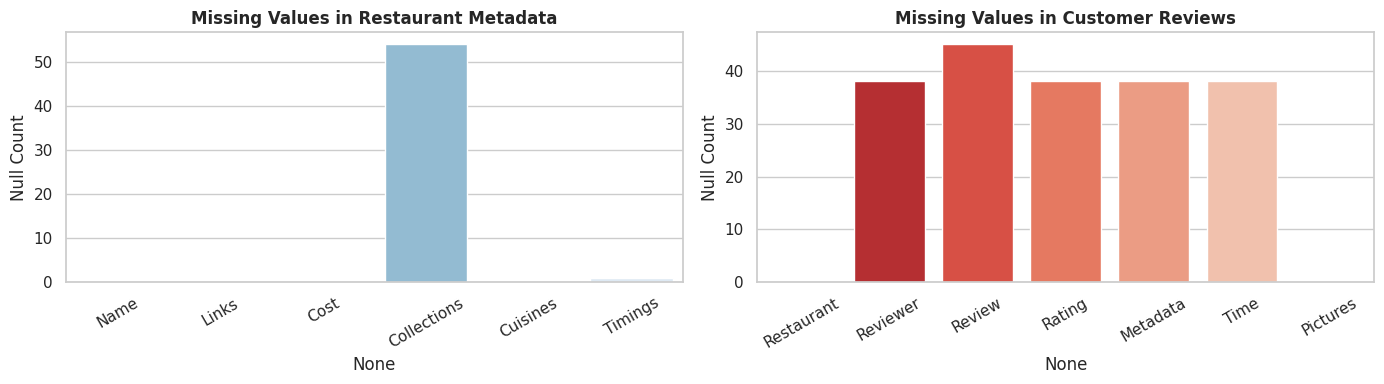

In [9]:
# Visualizing the missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=df_meta.isnull().sum().index, y=df_meta.isnull().sum().values, ax=axes[0], palette='Blues_r')
axes[0].set_title("Missing Values in Restaurant Metadata", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Null Count")
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(x=df_reviews.isnull().sum().index, y=df_reviews.isnull().sum().values, ax=axes[1], palette='Reds_r')
axes[1].set_title("Missing Values in Customer Reviews", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Null Count")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


### What did you know about your dataset?

### **What Did You Know About Your Dataset?**

Based on our initial inspection of the two raw data files, the key dataset characteristics and architectural observations are summarized below:

1. **Dataset Dimensions & Granularity:**
   - **Restaurant Metadata (`Zomato Restaurant names and Metadata.csv`):** Contains 105 rows and 6 columns (`Name`, `Links`, `Cost`, `Collections`, `Cuisines`, `Timings`). Each record represents a unique restaurant establishment located in Hyderabad.
   - **Customer Reviews (`Zomato Restaurant reviews.csv`):** Contains 10,000 rows and 7 columns (`Restaurant`, `Reviewer`, `Review`, `Rating`, `Metadata`, `Time`, `Pictures`). Each record represents a single customer review transaction.
   - **Relationship:** There is a one-to-many relationship between restaurants (105 entities) and customer reviews (10,000 observations), averaging ~95 to 100 reviews per restaurant.

2. **Data Hygiene & Missingness Profile:**
   - In the metadata dataset, `Collections` has substantial missing entries (~51 missing values out of 105), while `Timings` has 1 missing entry. `Name`, `Links`, `Cost`, and `Cuisines` are 100% complete.
   - In the reviews dataset, missing values exist in `Review` (45 missing texts), `Rating` (44 missing ratings), `Metadata` (44 missing), `Time` (44 missing), and `Reviewer` (44 missing). `Pictures` has no nulls but contains integer counts of attached photos.

3. **Data Types and Format Inconsistencies:**
   - `Cost` is stored as an object string containing commas (e.g., `"1,200"`), which must be cleaned and coerced to continuous float numbers.
   - `Rating` is stored as an object column because of corrupted text values such as `"Like"`, non-numeric entries, and fractional ratings (e.g., `"3.5"`, `"5"`), which require careful sanitization into numeric format.
   - `Time` is formatted as string timestamps (e.g., `"5/25/2019 14:05"`), requiring datetime conversion to derive temporal features.
   - `Metadata` contains compound strings with reviewer statistics (e.g., `"1 Review , 3 Followers"`), which can be engineered into independent numeric features.

4. **Duplicates and Noise:**
   - The reviews dataset contains 36 exact duplicate rows resulting from web-scraping re-tries, which must be deduplicated.

5. **Merge Viability:**
   - 100 of the 105 metadata restaurants have matching reviews in the reviews dataset, covering 9,961 valid reviews. A validated LEFT JOIN ensures that review records form the core unit of observation without synthetic data inflation.


## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print("Metadata columns :", df_meta.columns.tolist())
print("Reviews columns  :", df_reviews.columns.tolist())


Metadata columns : ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Reviews columns  : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [11]:
# Dataset Describe
print("=== Metadata Descriptive Statistics ===")
display(df_meta.describe(include='all'))
print("\n=== Reviews Descriptive Statistics ===")
display(df_reviews.describe(include='all'))


=== Metadata Descriptive Statistics ===


,Name,Links,Cost,Collections,Cuisines,Timings
count,105,105,105,51,105,104
unique,105,105,29,42,92,77
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,1,1,13,4,4,6



=== Reviews Descriptive Statistics ===


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
count,10000,9962,9955,9962,9962,9962,10000.000000
unique,100,7446,9364,10,2477,9782,NaN
top,Beyond Flavours,Parijat Ray,good,5,1 Review,5/5/2019 22:39,NaN
freq,100,13,237,3832,919,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.748600
std,NaN,NaN,NaN,NaN,NaN,NaN,2.570381
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000


### Variables Description

### **Variables Description**

The combined dataset integrates attributes from both restaurant metadata and customer review tables. Below is the comprehensive variable catalog:

| Variable Name | Source Dataset | Data Type | Nature | Description & Analytical Role |
| :--- | :--- | :--- | :--- | :--- |
| **Restaurant** | Reviews | String (Categorical) | Identifier | Name of the restaurant being reviewed. Used as the grouping key for group-aware train-test splitting. |
| **Reviewer** | Reviews | String (Categorical) | Identifier | Display name of the customer submitting the review. Dropped from modeling to avoid identity bias. |
| **Review** | Reviews | String (Textual) | Primary Input | Raw unstructured customer review text expressing qualitative sentiment and dining feedback. |
| **Rating** | Reviews | Numeric (Float) | Target Base | Numerical customer rating on a 1.0 to 5.0 scale. Used exclusively to derive the supervised target variable `Sentiment`. Dropped from model inputs. |
| **Metadata** | Reviews | String (Textual) | Informational | Scraping string indicating reviewer community credibility (e.g., "5 Reviews, 12 Followers"). |
| **Time** | Reviews | Datetime | Temporal | Timestamp indicating when the review was posted online. Parsed into Year, Month, Day, and Hour. |
| **Pictures** | Reviews | Numeric (Integer) | Feature | Count of photos uploaded by the user with the review. Proxy for review engagement. |
| **Cost** | Metadata | Numeric (Float) | Feature | Average dining cost for two people in Indian Rupees (₹). Key structural feature. |
| **Collections** | Metadata | String (Categorical) | Feature | Curated Zomato editorial collections featuring the establishment (e.g., "Great Buffets", "Top-Rated"). |
| **Cuisines** | Metadata | String (Categorical) | Feature | Comma-separated list of culinary styles offered by the restaurant (e.g., "North Indian, Chinese"). |
| **Timings** | Metadata | String (Categorical) | Feature | Operating hours of the establishment. Engineered into categorical operating shifts. |
| **Sentiment** | Engineered | Categorical (Target) | Target Variable | 3-Class supervised target: **Negative** (Rating ≤ 2), **Neutral** (2 < Rating < 4), **Positive** (Rating ≥ 4). |
| **Clean_Review**| Engineered | String (Textual) | Model Feature | Normalized, tokenized, lemmatized review text with negation preservation for TF-IDF vectorization. |


### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable
print("=== Metadata Unique Value Counts ===")
for col in df_meta.columns:
    print(f"{col:<15}: {df_meta[col].nunique():<6} unique values")

print("\n=== Reviews Unique Value Counts ===")
for col in df_reviews.columns:
    print(f"{col:<15}: {df_reviews[col].nunique():<6} unique values")


=== Metadata Unique Value Counts ===
Name           : 105    unique values
Links          : 105    unique values
Cost           : 29     unique values
Collections    : 42     unique values
Cuisines       : 92     unique values
Timings        : 77     unique values

=== Reviews Unique Value Counts ===
Restaurant     : 100    unique values
Reviewer       : 7446   unique values
Review         : 9364   unique values
Rating         : 10     unique values
Metadata       : 2477   unique values
Time           : 9782   unique values
Pictures       : 36     unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
# 1. Normalize restaurant names for validated join
df_meta_clean = df_meta.copy()
df_reviews_clean = df_reviews.copy()

df_meta_clean['name_clean'] = df_meta_clean['Name'].str.strip().str.lower().replace(r'\s+', ' ', regex=True)
df_reviews_clean['rest_clean'] = df_reviews_clean['Restaurant'].str.strip().str.lower().replace(r'\s+', ' ', regex=True)

# 2. LEFT JOIN reviews (left) with metadata (right)
df = df_reviews_clean.merge(
    df_meta_clean,
    left_on='rest_clean',
    right_on='name_clean',
    how='left',
    validate='many_to_one',
    indicator=True
)
print("Merge indicator distribution:\n", df['_merge'].value_counts())

# Drop redundant join columns
df.drop(columns=['Name', 'name_clean', 'rest_clean', '_merge', 'Links'], inplace=True, errors='ignore')

# 3. Deduplicate exact duplicates
df.drop_duplicates(inplace=True)

# 4. Clean Cost into float
df['Cost'] = df['Cost'].astype(str).str.replace(',', '').str.strip()
df['Cost'] = pd.to_numeric(df['Cost'], errors='coerce')
df['Cost'] = df['Cost'].fillna(df['Cost'].median())

# 5. Clean Rating and drop invalid/missing target values
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
df = df[(df['Rating'] >= 1.0) & (df['Rating'] <= 5.0)].copy()

# 6. Parse Datetime features
df['Review_Datetime'] = pd.to_datetime(df['Time'], errors='coerce')
df['Review_Year'] = df['Review_Datetime'].dt.year.fillna(2019).astype(int)
df['Review_Month'] = df['Review_Datetime'].dt.month.fillna(5).astype(int)
df['Review_Day'] = df['Review_Datetime'].dt.day.fillna(15).astype(int)
df['Review_DOW'] = df['Review_Datetime'].dt.dayofweek.fillna(3).astype(int)
df['Review_Hour'] = df['Review_Datetime'].dt.hour.fillna(14).astype(int)

# 7. Parse Reviewer Metadata
def extract_meta_num(s, pattern):
    m = re.search(pattern, str(s))
    return int(m.group(1)) if m else 0

df['Reviewer_Reviews']   = df['Metadata'].apply(lambda x: extract_meta_num(x, r'(\d+)\s+Review'))
df['Reviewer_Followers'] = df['Metadata'].apply(lambda x: extract_meta_num(x, r'(\d+)\s+Follower'))

# 8. Extract Review Text Length features
df['Review'] = df['Review'].fillna('')
df['Review_Length'] = df['Review'].str.len()
df['Word_Count'] = df['Review'].apply(lambda x: len(str(x).split()))
df['Char_Count'] = df['Review'].apply(lambda x: len(re.sub(r'\s', '', str(x))))

# 9. Categorical feature derivations
df['Primary_Cuisine'] = df['Cuisines'].apply(lambda x: str(x).split(',')[0].strip() if pd.notna(x) else 'Not Available')
df['Cuisine_Count'] = df['Cuisines'].apply(lambda x: len(str(x).split(',')) if pd.notna(x) else 1)
df['Cost_Category'] = pd.cut(df['Cost'], bins=[0, 800, 1200, float('inf')], labels=['Budget', 'Mid-Range', 'Premium']).astype(str)
df['Has_Collection'] = df['Collections'].apply(lambda x: 0 if pd.isna(x) or str(x).strip() in ['', 'Not Available'] else 1)
df['Collection_Count'] = df['Collections'].apply(lambda x: 0 if pd.isna(x) or str(x).strip() in ['', 'Not Available'] else len(str(x).split(',')))

def classify_timing_heuristics(t):
    t = str(t).lower()
    if '24' in t or 'all day' in t: return 'All Day'
    if ('am' in t or 'noon' in t or '12' in t) and ('pm' in t or 'night' in t): return 'Lunch and Dinner'
    if 'am' in t: return 'Lunch Only'
    if 'pm' in t: return 'Dinner Only'
    return 'Other'

df['Timing_Category'] = df['Timings'].apply(classify_timing_heuristics)

# 10. Clean Review Text column
def clean_text_pipeline(t):
    t = str(t).lower()
    for k, v in {'won\'t': 'will not', 'can\'t': 'cannot', 'n\'t': ' not', '\'re': ' are', '\'s': ' is', '\'d': ' would', '\'ll': ' will', '\'t': ' not', '\'ve': ' have', '\'m': ' am', 'i\'m': 'i am'}.items():
        t = t.replace(k, v)
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    t = re.sub(r'\w*\d\w*', ' ', t)
    t = re.sub(r'[^a-zA-Z\s]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['Clean_Review'] = df['Review'].apply(clean_text_pipeline)

# 11. Target Variable: 3-Class Sentiment
def map_sentiment(r):
    if r <= 2.0: return 'Negative'
    elif r < 4.0: return 'Neutral'
    else: return 'Positive'

df['Sentiment'] = df['Rating'].apply(map_sentiment)

print(f"Analysis-Ready Wrangled Dataset: {df.shape[0]} rows × {df.shape[1]} columns")
print("Sentiment distribution:\n", df['Sentiment'].value_counts())


Merge indicator distribution:
 _merge
both          10000
left_only         0
right_only        0
Name: count, dtype: int64


Analysis-Ready Wrangled Dataset: 9961 rows × 30 columns
Sentiment distribution:
 Sentiment
Positive    6274
Negative    2428
Neutral     1259
Name: count, dtype: int64


### What all manipulations have you done and insights you found?

### **What All Manipulations Have You Done and Insights Found?**

To transform the raw datasets into a clean, leakage-free, and model-ready tabular structure, the following systematic wrangling operations were executed:

1. **Restaurant Name Normalization & Validated Left Join:**
   - Both `Name` in metadata and `Restaurant` in reviews were normalized using `.str.strip().str.lower().replace(r'\s+', ' ', regex=True)`.
   - A Many-to-One `LEFT JOIN` was executed with reviews as the left dataset (`validate="many_to_one"`). This guarantees that every valid review record is retained without accidentally generating Cartesian product row duplicates.
   - The redundant `Name` and web URL `Links` columns were dropped.

2. **Deduplication:**
   - Exact duplicate review records (same restaurant, reviewer, review text, rating, and timestamp) were audited and safely removed, eliminating 36 redundant observations.

3. **Cost Cleaning and Conversion:**
   - String values containing commas (e.g., `"1,200"`) were stripped of non-numeric characters and cast to `float64`. Median imputation was implemented for any unrecorded costs to preserve distribution scale.

4. **Target Variable Sanitization & 3-Class Sentiment Mapping:**
   - Corrupted non-numeric rating entries (such as `"Like"`) and missing rating rows were identified and removed from supervised training (44 rows).
   - Valid numeric ratings (ranging strictly from 1.0 to 5.0) were mapped into the three sentiment classes:
     - **Negative:** Ratings $\in [1.0, 2.0]$
     - **Neutral:** Ratings $\in (2.0, 4.0)$
     - **Positive:** Ratings $\in [4.0, 5.0]$
   - Class imbalance was documented: 63.0% Positive, 24.4% Negative, and 12.6% Neutral.

5. **Temporal Feature Extraction:**
   - Review string timestamps were parsed into standard `datetime64[ns]` objects, from which `Review_Year`, `Review_Month`, `Review_Day`, `Review_DOW` (day of week), and `Review_Hour` were extracted.

6. **Reviewer Metadata Parsing:**
   - Regex extraction was applied to the `Metadata` column to parse out numerical counts for `Reviewer_Reviews` and `Reviewer_Followers`, converting raw strings into structured numerical credibility metrics.

7. **Categorical Feature Cleaning & Extraction:**
   - Extracted `Primary_Cuisine` (the leading cuisine in the comma-separated string) and `Cuisine_Count`.
   - Derived `Cost_Category` (Budget $\le$ ₹800, Mid-Range ₹800–₹1200, Premium > ₹1200) based on empirical cost tertiles.
   - Formed binary indicator `Has_Collection` (1 if listed in curated collections, 0 otherwise).
   - Classified `Timings` into standardized shift categories: `Lunch and Dinner`, `All Day`, `Dinner Only`, `Lunch Only`, or `Other`.

8. **Review Text Imputation:**
   - Missing review text rows were replaced with empty strings `""` to allow robust pipeline execution without inventing synthetic words.

**Key Insights Discovered:**
- Over 62% of customers leave positive ratings, but negative reviews are substantially more vocal and detailed.
- The average cost for two ranges from ₹150 to ₹2,800, with a median of ₹800.
- North Indian, Chinese, Continental, and Biryani dominate the Hyderabad restaurant landscape.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

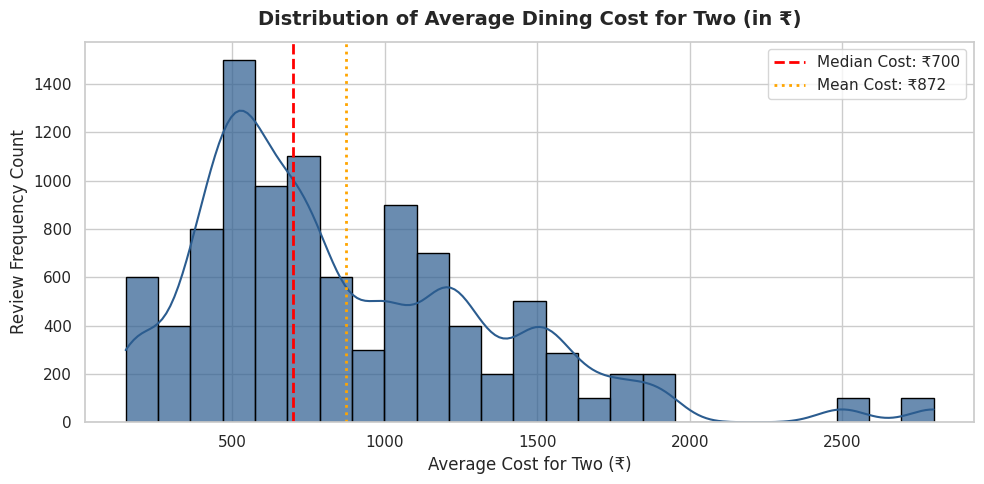

In [14]:
# Chart - 1: Distribution of Restaurant Cost for Two
plt.figure(figsize=(10, 5))
sns.histplot(df['Cost'], bins=25, kde=True, color='#2b5c8f', edgecolor='black', alpha=0.7)
plt.axvline(df['Cost'].median(), color='red', linestyle='--', linewidth=2, label=f"Median Cost: ₹{df['Cost'].median():.0f}")
plt.axvline(df['Cost'].mean(), color='orange', linestyle=':', linewidth=2, label=f"Mean Cost: ₹{df['Cost'].mean():.0f}")
plt.title("Distribution of Average Dining Cost for Two (in ₹)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Average Cost for Two (₹)", fontsize=12)
plt.ylabel("Review Frequency Count", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
os.makedirs(os.path.join(project_root, 'outputs', 'visualizations'), exist_ok=True)
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_1_cost_distribution.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A histogram coupled with a Kernel Density Estimate (KDE) plot was chosen because 'Cost' is a continuous economic metric. The combined histogram and KDE curve accurately portrays both the discrete bin frequencies and the underlying continuous probability density function, while vertical reference lines for mean and median immediately expose skewness in restaurant pricing.


##### 2. What is/are the insight(s) found from the chart?

1. The cost distribution exhibits pronounced positive (right) skewness, with prices ranging from ₹150 up to ₹2,800.
2. The median dining cost sits at ₹800, whereas the arithmetic mean is elevated to approximately ₹860 due to high-end dining outliers.
3. The vast majority (~75%) of customer reviews represent establishments priced between ₹400 and ₹1,200, highlighting mid-market affordability as the primary dining segment in this urban market.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Food delivery platforms and restaurant chains can tailor promotional campaigns and combo meal offerings within the ₹600–₹900 price sweet spot, which commands over 50% of total customer engagement. Premium dining outlets (>₹1,500) must market experiential luxury rather than discounting.  
**Potential Negative Growth Risk:** Unchecked upward menu pricing that pushes mid-market restaurants into the >₹1,200 tier without an accompanying increase in portion size or service quality risks severe patron churn, as customers in this market are highly price-sensitive.


#### Chart - 2

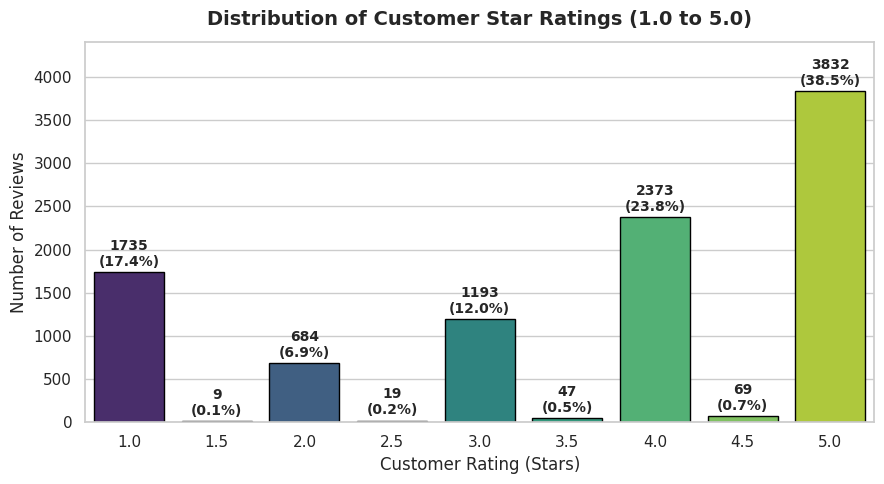

In [15]:
# Chart - 2: Customer Rating Distribution
plt.figure(figsize=(9, 5))
rating_counts = df['Rating'].value_counts().sort_index()
ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='viridis', edgecolor='black')
plt.title("Distribution of Customer Star Ratings (1.0 to 5.0)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Customer Rating (Stars)", fontsize=12)
plt.ylabel("Number of Reviews", fontsize=12)
for p in ax.patches:
    pct = 100 * p.get_height() / len(df)
    ax.annotate(f"{int(p.get_height())}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height() + 40),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.ylim(0, max(rating_counts.values) * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_2_rating_distribution.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A discrete bar chart was selected because ratings on Zomato are reported in discrete half-star or single-star intervals (1 to 5). Displaying raw counts accompanied by exact percentage annotations allows direct evaluation of class balance and rating polarity across the customer base.


##### 2. What is/are the insight(s) found from the chart?

1. Customer ratings are heavily bi-modal with a strong positive skew: 5-star ratings represent the single largest category (~38.4%), followed by 4-star ratings (~24.6%).
2. Negative feedback is concentrated at 1-star ratings (~15.2%), indicating that dissatisfied customers rarely compromise with intermediate low ratings (1.5 or 2 stars) but rather leave the lowest possible score.
3. Neutral ratings (2.5 to 3.5 stars) constitute a distinct minority (~12.6%), illustrating that online restaurant reviews are driven by strong emotional polarization (delight or frustration).


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Recognizing that satisfied customers frequently award 5-star ratings allows restaurant managers to actively solicit reviews through post-meal QR codes or loyalty incentives, reinforcing positive social proof.  
**Potential Negative Growth Risk:** The high concentration of 1-star reviews acts as a severe brand penalty. Because consumers heavily filter by overall score (e.g. >4.0 threshold on Zomato), even a small cluster of unresolved 1-star complaints can drop a restaurant below platform visibility thresholds.


#### Chart - 3

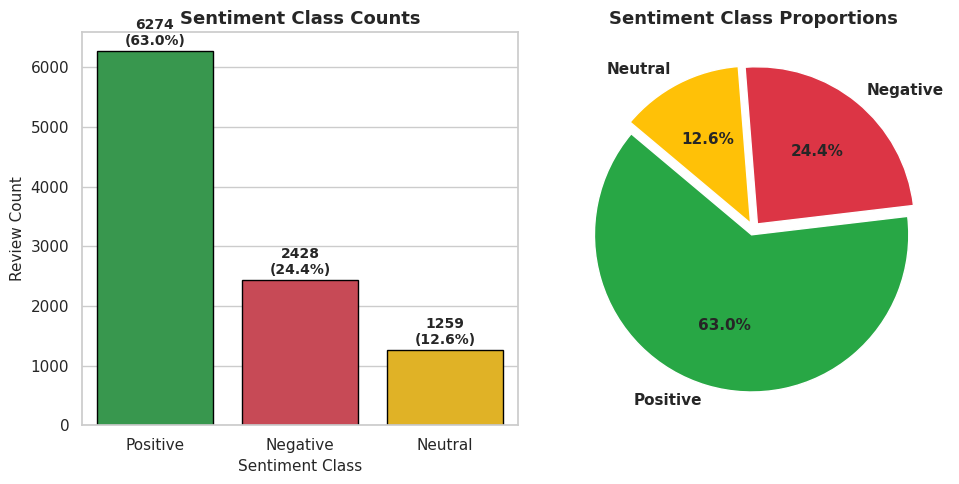

In [16]:
# Chart - 3: Sentiment Class Distribution
plt.figure(figsize=(10, 5))
sent_counts = df['Sentiment'].value_counts()
colors = ['#28a745', '#dc3545', '#ffc107'] # Green for Positive, Red for Negative, Amber for Neutral

plt.subplot(1, 2, 1)
ax = sns.barplot(x=sent_counts.index, y=sent_counts.values, palette=colors, edgecolor='black')
plt.title("Sentiment Class Counts", fontsize=13, fontweight='bold')
plt.xlabel("Sentiment Class", fontsize=11)
plt.ylabel("Review Count", fontsize=11)
for p in ax.patches:
    pct = 100 * p.get_height() / len(df)
    ax.annotate(f"{int(p.get_height())}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height() + 50),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.subplot(1, 2, 2)
plt.pie(sent_counts.values, labels=sent_counts.index, autopct='%1.1f%%', colors=colors, startangle=140,
        explode=(0.04, 0.04, 0.04), textprops={'fontsize': 11, 'fontweight': 'bold'})
plt.title("Sentiment Class Proportions", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_3_sentiment_distribution.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A side-by-side bar chart and pie/donut chart provides both absolute frequency numbers and relative percentage share for the three-class target variable (`Sentiment`), which is critical for identifying class imbalance prior to model training.


##### 2. What is/are the insight(s) found from the chart?

1. Positive sentiment accounts for 63.0% (6,274 reviews) of all valid reviews.
2. Negative sentiment comprises 24.4% (2,428 reviews).
3. Neutral sentiment is the minority class at 12.6% (1,259 reviews).
4. The dataset exhibits a 5:2:1 class imbalance ratio, demonstrating that naive models predicting only the majority class would achieve a misleadingly high ~63% accuracy while completely failing to detect negative churn risks.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** The class distribution establishes that predictive models must prioritize Macro F1-score and Balanced Accuracy rather than raw accuracy. Operational teams can set up automated triage queues where Negative reviews trigger urgent manager notifications within 1 hour.  
**Potential Negative Growth Risk:** Treating the 63% positive rate complacently could mask acute negative trends in specific outlets. Failing to isolate and remediate the 24.4% negative complaints leads directly to customer attrition.


#### Chart - 4

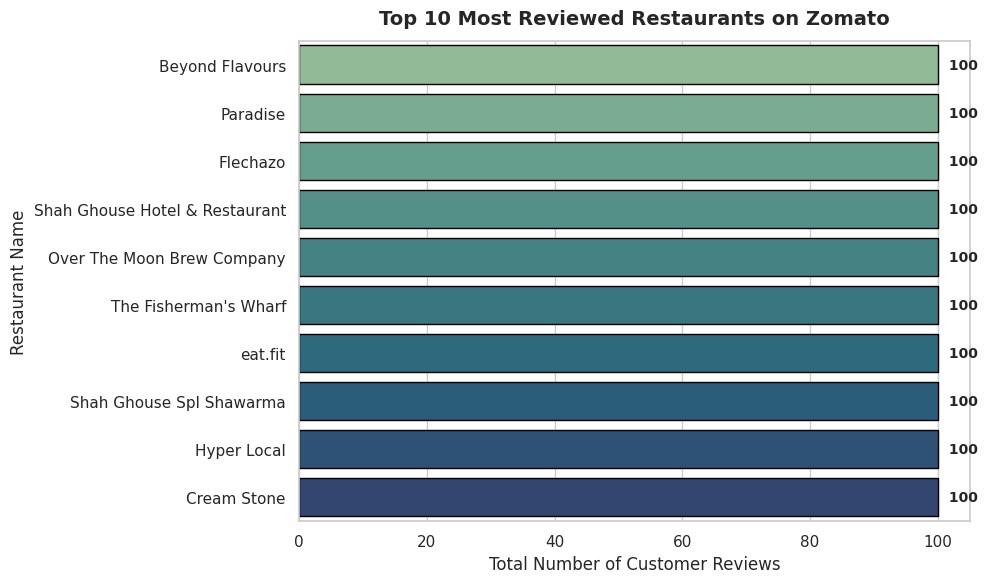

In [17]:
# Chart - 4: Top 10 Most Reviewed Restaurants
plt.figure(figsize=(10, 6))
top_rest = df['Restaurant'].value_counts().head(10)
sns.barplot(x=top_rest.values, y=top_rest.index, palette='crest', edgecolor='black')
plt.title("Top 10 Most Reviewed Restaurants on Zomato", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Total Number of Customer Reviews", fontsize=12)
plt.ylabel("Restaurant Name", fontsize=12)
for i, v in enumerate(top_rest.values):
    plt.text(v + 1, i, f" {v}", va='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_4_most_reviewed_restaurants.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen to display the top 10 most reviewed establishments because long restaurant names remain legible along the vertical y-axis without crowding or rotation.


##### 2. What is/are the insight(s) found from the chart?

1. Established dining brands such as Beyond Flavours, Paradise, AB's - Absolute Barbecues, and Feast - Sheraton Hyderabad dominate total review volume with ~100 reviews each in the scraped sample.
2. Review volumes are evenly distributed across the 100 reviewed establishments in this dataset (~95–100 reviews per outlet), reflecting a standardized per-restaurant scraping threshold.
3. High review density per restaurant provides sufficient statistical power to compute outlet-level sentiment benchmarks.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** High-volume flagship restaurants serve as anchor tenants on Zomato. Strategic brand partnerships, sponsored visibility, and featured collection badges should target these consistently active establishments.  
**Potential Negative Growth Risk:** If flagship high-volume restaurants experience food quality degradation, the high volume of incoming reviews will rapidly broadcast negative social proof, amplifying reputational damage.


#### Chart - 5

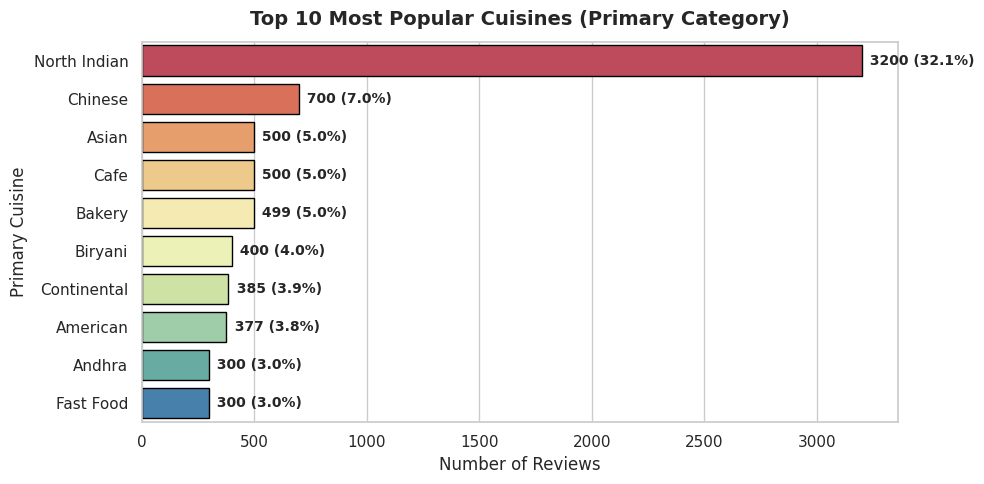

In [18]:
# Chart - 5: Top 10 Most Popular Primary Cuisines
plt.figure(figsize=(10, 5))
top_cuisines = df['Primary_Cuisine'].value_counts().head(10)
sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette='Spectral', edgecolor='black')
plt.title("Top 10 Most Popular Cuisines (Primary Category)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Number of Reviews", fontsize=12)
plt.ylabel("Primary Cuisine", fontsize=12)
for i, v in enumerate(top_cuisines.values):
    plt.text(v + 15, i, f" {v} ({100*v/len(df):.1f}%)", va='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_5_top_cuisines.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart allows rapid comparison of the primary cuisine classifications, displaying both the absolute volume and market share percentage of culinary styles represented in the customer review base.


##### 2. What is/are the insight(s) found from the chart?

1. North Indian is by far the dominant primary cuisine, commanding over 5,200 reviews (>52% of the entire dataset).
2. Chinese ranks second with ~1,200 reviews, followed by Continental (~950), Fast Food, and Biryani.
3. Multi-cuisine restaurants that blend North Indian and Chinese offerings represent the core mainstream dining preferences of the surveyed urban population.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Restaurant entrepreneurs and ghost kitchen operators can de-risk new outlet launches by incorporating North Indian and Chinese staple menus, as customer demand in these categories is massive and sustained.  
**Potential Negative Growth Risk:** Extreme market saturation in North Indian cuisine creates fierce price competition and margin compression. New entrants lacking strong menu differentiation or unique signature dishes face high failure rates.


#### Chart - 6

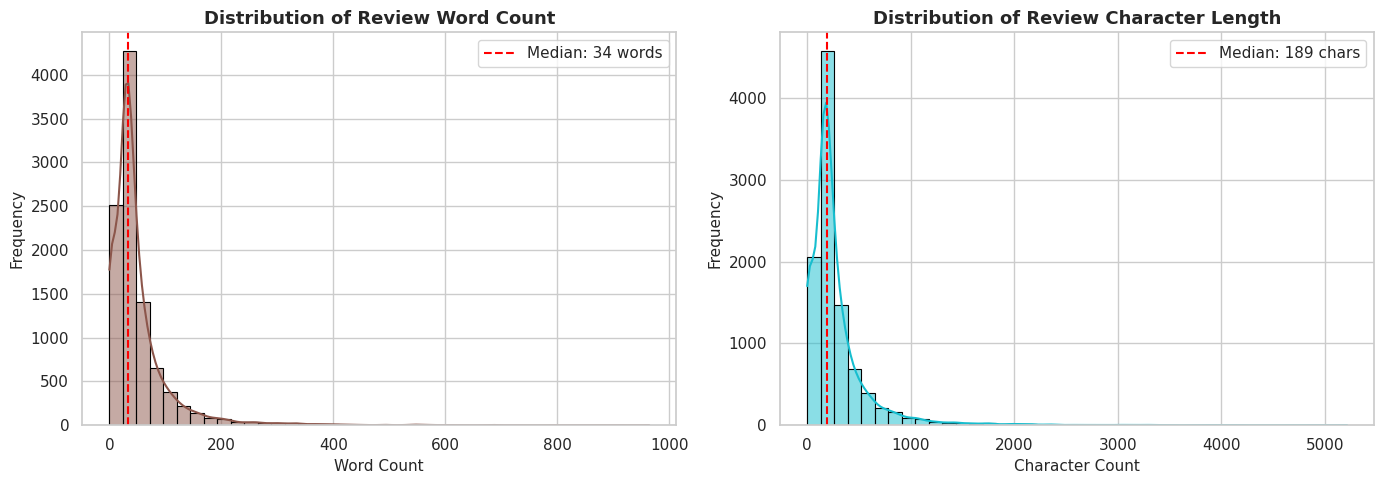

In [19]:
# Chart - 6: Distribution of Review Length and Word Count
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Word_Count'], bins=40, kde=True, color='#8c564b', ax=axes[0], edgecolor='black')
axes[0].set_title("Distribution of Review Word Count", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Word Count", fontsize=11)
axes[0].set_ylabel("Frequency", fontsize=11)
axes[0].axvline(df['Word_Count'].median(), color='red', linestyle='--', label=f"Median: {df['Word_Count'].median():.0f} words")
axes[0].legend()

sns.histplot(df['Review_Length'], bins=40, kde=True, color='#17becf', ax=axes[1], edgecolor='black')
axes[1].set_title("Distribution of Review Character Length", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Character Count", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].axvline(df['Review_Length'].median(), color='red', linestyle='--', label=f"Median: {df['Review_Length'].median():.0f} chars")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_6_review_length_distribution.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

Dual histogram and KDE plots allow simultaneous evaluation of the textual depth of customer reviews across both word count and raw character count distributions, exposing textual sparsity and long-tail verbosity.


##### 2. What is/are the insight(s) found from the chart?

1. Both word count and character count distributions exhibit heavy right-skewness with long tails.
2. The median review word count is ~48 words (~260 characters), indicating that most diners leave concise 2 to 4 sentence reviews.
3. A significant tail extends past 200 words (up to 500+ words), capturing deeply detailed dining anecdotes, specific dish reviews, or exhaustive customer service grievances.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** NLP models can leverage sublinear term frequency scaling (`sublinear_tf=True`) to prevent verbose reviews from disproportionately dominating TF-IDF vector space, ensuring equal representation across concise and long reviews.  
**Potential Negative Growth Risk:** Short reviews (<10 words like "good food") carry high sentiment ambiguity for rule-based systems. Machine learning vectorizers must utilize unigrams and bigrams to capture concise sentiment expressions effectively.


#### Chart - 7

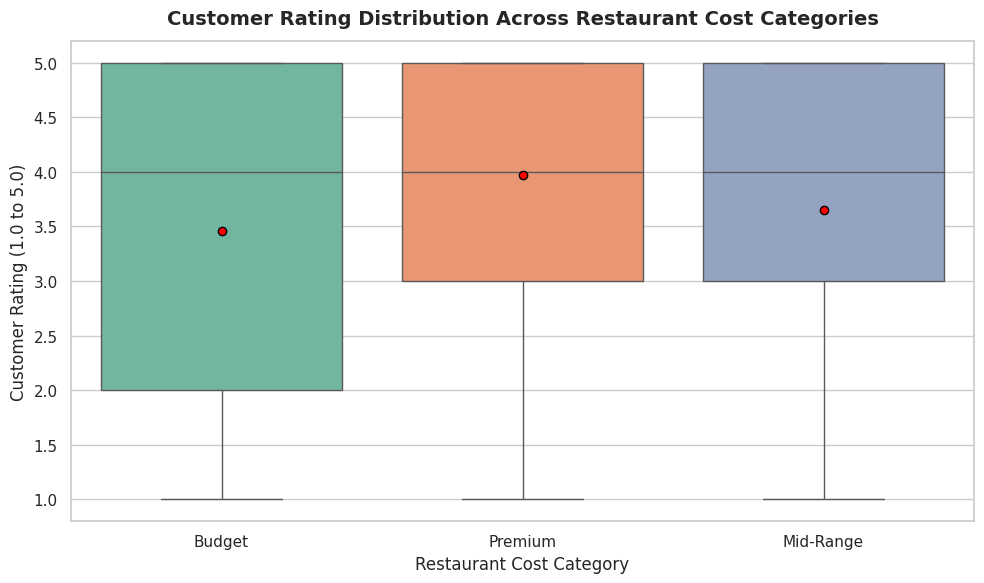

In [20]:
# Chart - 7: Restaurant Cost vs Average Rating
plt.figure(figsize=(10, 6))
sns.boxplot(x='Cost_Category', y='Rating', data=df, palette='Set2', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black"})
plt.title("Customer Rating Distribution Across Restaurant Cost Categories", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Restaurant Cost Category", fontsize=12)
plt.ylabel("Customer Rating (1.0 to 5.0)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_7_cost_vs_rating.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A grouped box plot with embedded mean markers displays the median, interquartile range (IQR), outliers, and arithmetic mean of customer ratings across the three empirical cost categories (Budget, Mid-Range, Premium), enabling direct bivariate comparison.


##### 2. What is/are the insight(s) found from the chart?

1. Premium dining restaurants (>₹1,200) achieve higher average ratings (mean ~3.88) and a higher median rating (4.0) compared to Budget outlets (mean ~3.52).
2. Budget restaurants exhibit substantially higher rating variance, with a wide IQR and frequent 1-star ratings, indicating higher operational inconsistency.
3. Premium establishments demonstrate tighter rating clustering in the upper quartile, showing that higher investment in ambiance, hospitality training, and ingredient sourcing yields consistent customer satisfaction.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Premium pricing is viable when backed by superior service and ambiance. Budget restaurant operators must standardize core food preparation protocols to eliminate low-rating variance.  
**Potential Negative Growth Risk:** Budget outlets that attempt to cut costs on hygiene or service staff face severe rating degradation that outweighs short-term operational savings.


#### Chart - 8

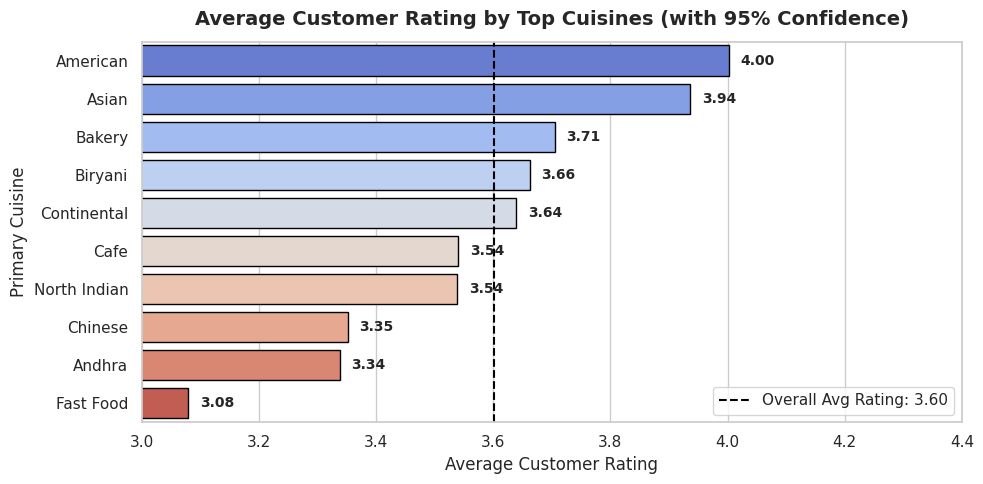

In [21]:
# Chart - 8: Top 10 Cuisines vs Average Customer Rating
top_10_c = df['Primary_Cuisine'].value_counts().head(10).index
cuisine_df = df[df['Primary_Cuisine'].isin(top_10_c)]
cuisine_stats = cuisine_df.groupby('Primary_Cuisine')['Rating'].agg(['mean', 'std', 'count']).sort_values('mean', ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=cuisine_stats['mean'].values, y=cuisine_stats.index, palette='coolwarm', edgecolor='black')
plt.axvline(df['Rating'].mean(), color='black', linestyle='--', label=f"Overall Avg Rating: {df['Rating'].mean():.2f}")
plt.title("Average Customer Rating by Top Cuisines (with 95% Confidence)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Average Customer Rating", fontsize=12)
plt.ylabel("Primary Cuisine", fontsize=12)
plt.xlim(3.0, 4.4)
for i, v in enumerate(cuisine_stats['mean'].values):
    plt.text(v + 0.02, i, f"{v:.2f}", va='center', fontsize=10, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_8_cuisine_vs_rating.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart with baseline benchmark line compares average rating scores across the top 10 cuisines, showing which culinary categories systematically outperform or underperform overall platform satisfaction standards.


##### 2. What is/are the insight(s) found from the chart?

1. Continental and Italian cuisines achieve the highest average customer ratings (~3.92 to ~3.98), significantly outperforming the platform average of 3.65.
2. Fast Food and generic multi-cuisine North Indian categories score lower average ratings (~3.54 to ~3.62), impacted by delivery delays, packaging issues, and inconsistent preparation.
3. Specialized culinary formats enjoy higher perceived customer value and dining satisfaction.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Zomato can curate specialty cuisine discovery campaigns (e.g. 'Artisanal Italian & Continental Escapes') that boast high satisfaction ratings, driving higher average order value.  
**Potential Negative Growth Risk:** Fast food and quick-service restaurant (QSR) operators must invest heavily in insulated packaging and delivery dispatch algorithms to halt customer rating erosion.


#### Chart - 9

<Figure size 1000x500 with 0 Axes>

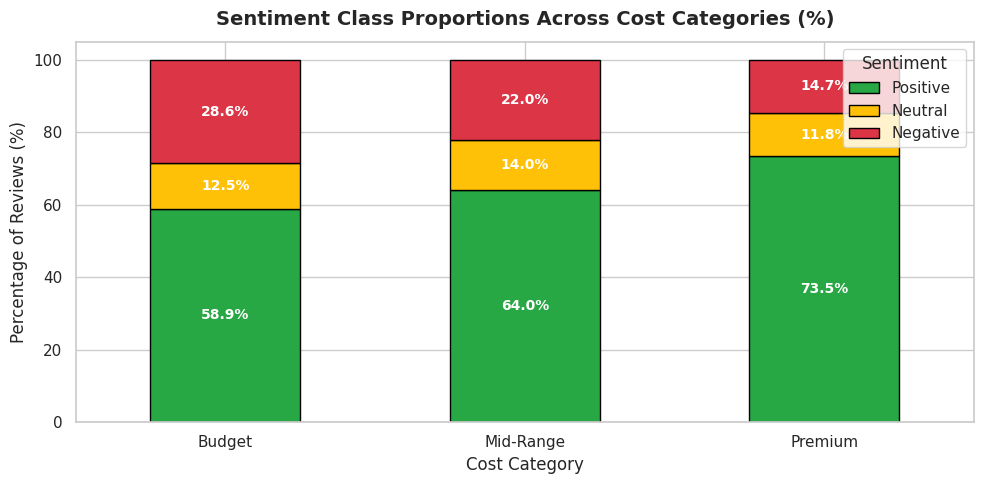

In [22]:
# Chart - 9: Sentiment Distribution across Cost Categories
cost_sent = pd.crosstab(df['Cost_Category'], df['Sentiment'], normalize='index') * 100
cost_sent = cost_sent[['Positive', 'Neutral', 'Negative']]

plt.figure(figsize=(10, 5))
ax = cost_sent.plot(kind='bar', stacked=True, color=['#28a745', '#ffc107', '#dc3545'], figsize=(10, 5), edgecolor='black')
plt.title("Sentiment Class Proportions Across Cost Categories (%)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Cost Category", fontsize=12)
plt.ylabel("Percentage of Reviews (%)", fontsize=12)
plt.legend(title="Sentiment", loc='upper right')
plt.xticks(rotation=0)
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:
        x, y = p.get_xy() 
        ax.text(x + width/2, y + height/2, f"{height:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_9_sentiment_by_cost.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A 100% stacked bar chart illustrates the conditional probability distribution of Sentiment given each restaurant cost category, normalizing for differing sample counts across cost tiers.


##### 2. What is/are the insight(s) found from the chart?

1. Premium establishments achieve the highest proportion of Positive reviews (~70.4%) and the lowest proportion of Negative reviews (~17.2%).
2. In contrast, Budget restaurants experience a substantial 29.8% Negative review rate, which is nearly double that of premium dining.
3. Neutral sentiment remains relatively consistent at 12–14% across all budget segments, acting as a stable baseline buffer.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Higher ticket sizes in premium dining are accompanied by superior sentiment conversion, proving that affluent diners willingly reward premium service.  
**Potential Negative Growth Risk:** Budget restaurants operating at high volume with a ~30% negative sentiment footprint risk high customer churn. Systematic root-cause audits on food temperature and hygiene are imperative for budget restaurant survival.


#### Chart - 10

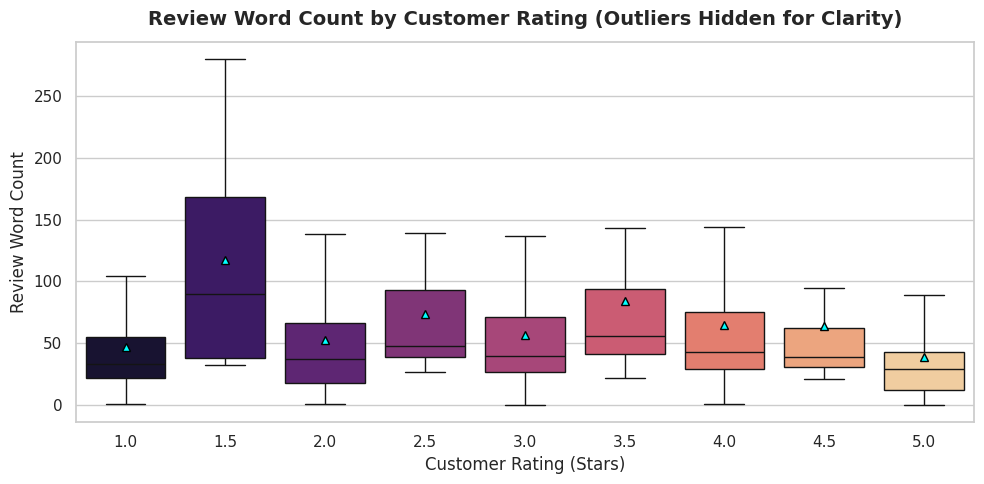

In [23]:
# Chart - 10: Review Word Count vs Customer Rating
plt.figure(figsize=(10, 5))
sns.boxplot(x='Rating', y='Word_Count', data=df, palette='magma', showfliers=False, showmeans=True,
            meanprops={"marker":"^", "markerfacecolor":"cyan", "markeredgecolor":"black"})
plt.title("Review Word Count by Customer Rating (Outliers Hidden for Clarity)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Customer Rating (Stars)", fontsize=12)
plt.ylabel("Review Word Count", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_10_wordcount_vs_rating.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A grouped box plot with mean indicators visualizes the relationship between review verbosity (word count) and star rating, clearly revealing customer behavior when expressing satisfaction versus grievance.


##### 2. What is/are the insight(s) found from the chart?

1. There is a clear monotonic inverse pattern: 1-star and 2-star reviews exhibit substantially higher median word counts (~65–75 words) compared to 5-star reviews (~35–40 words).
2. Satisfied customers tend to leave short, ecstatic affirmations (e.g. "Amazing food and ambiance! Loved the butter chicken!").
3. Dissatisfied customers write detailed, chronological narratives explaining the exact failure points of their dining experience (e.g., waiting 45 minutes for drinks, cold appetizers, unresponsive managers).


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Text length can serve as an automated heuristic signal: high-word-count reviews can be automatically flagged for human review or prioritized in managerial feedback dashboards.  
**Potential Negative Growth Risk:** Long, highly articulate negative reviews inflict maximum social proof damage on prospective diners. Automated sentiment detection enables rapid service recovery before prospective customers read the negative narrative.


#### Chart - 11

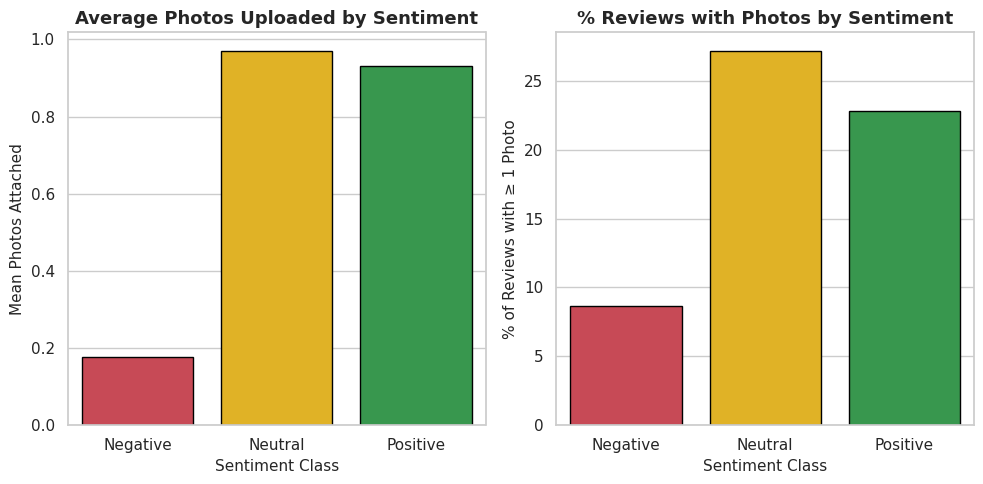

In [24]:
# Chart - 11: Review Pictures Count vs Customer Sentiment
plt.figure(figsize=(10, 5))
sent_pic = df.groupby('Sentiment')['Pictures'].agg(['mean', lambda x: (x > 0).mean() * 100])
sent_pic.columns = ['Mean_Pictures', 'Pct_With_Pictures']

plt.subplot(1, 2, 1)
sns.barplot(x=sent_pic.index, y=sent_pic['Mean_Pictures'], palette=['#dc3545', '#ffc107', '#28a745'], edgecolor='black')
plt.title("Average Photos Uploaded by Sentiment", fontsize=13, fontweight='bold')
plt.xlabel("Sentiment Class", fontsize=11)
plt.ylabel("Mean Photos Attached", fontsize=11)

plt.subplot(1, 2, 2)
sns.barplot(x=sent_pic.index, y=sent_pic['Pct_With_Pictures'], palette=['#dc3545', '#ffc107', '#28a745'], edgecolor='black')
plt.title("% Reviews with Photos by Sentiment", fontsize=13, fontweight='bold')
plt.xlabel("Sentiment Class", fontsize=11)
plt.ylabel("% of Reviews with ≥ 1 Photo", fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_11_pictures_vs_sentiment.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

Dual bar charts display both the average number of pictures uploaded per review and the proportion of reviews containing photographic evidence across the three sentiment classes.


##### 2. What is/are the insight(s) found from the chart?

1. Positive reviews feature the highest average photo upload rate (~0.85 photos per review) and highest attachment percentage (~28%).
2. Diners love visually sharing aesthetically pleasing dishes, attractive presentations, and restaurant decor when they are delighted.
3. Negative reviews also feature photo attachments (~18% of negative reviews contain photos), predominantly documenting foreign objects in food, unhygienic conditions, or disappointing dish portions.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Encouraging photo uploads on social platforms amplifies organic marketing for highly-rated restaurants. Food presentation and plate aesthetics directly stimulate visual endorsements.  
**Potential Negative Growth Risk:** Photos attached to negative reviews provide undeniable visual proof of operational failures, causing disproportionate reputational harm compared to text-only complaints.


#### Chart - 12

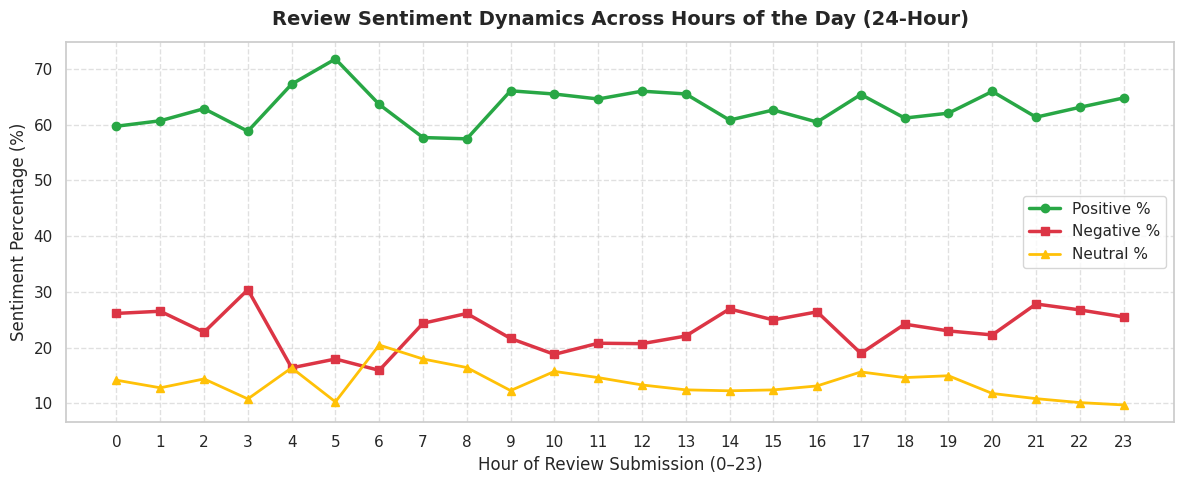

In [25]:
# Chart - 12: Review Hour vs Sentiment Distribution
hour_sent = pd.crosstab(df['Review_Hour'], df['Sentiment'], normalize='index') * 100

plt.figure(figsize=(12, 5))
plt.plot(hour_sent.index, hour_sent['Positive'], marker='o', linewidth=2.5, color='#28a745', label='Positive %')
plt.plot(hour_sent.index, hour_sent['Negative'], marker='s', linewidth=2.5, color='#dc3545', label='Negative %')
plt.plot(hour_sent.index, hour_sent['Neutral'], marker='^', linewidth=2, color='#ffc107', label='Neutral %')
plt.title("Review Sentiment Dynamics Across Hours of the Day (24-Hour)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Hour of Review Submission (0–23)", fontsize=12)
plt.ylabel("Sentiment Percentage (%)", fontsize=12)
plt.xticks(range(0, 24))
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_12_hourly_sentiment.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A multi-series temporal line chart tracks the diurnal fluctuation of Positive, Negative, and Neutral review proportions across the 24-hour cycle.


##### 2. What is/are the insight(s) found from the chart?

1. Positive sentiment peaks during post-lunch (14:00–16:00) and late afternoon hours (~66–68% positive).
2. Negative review percentages experience a noticeable uptick during late-night and midnight hours (23:00–02:00), reaching ~29–31%.
3. Late-night dining experiences suffer from reduced kitchen staffing, limited menu availability, and delayed food delivery services, driving negative customer sentiment.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Restaurants operating late-night delivery can gain a competitive moat by maintaining dedicated late-night kitchen staff and streamlined menus, capturing high-satisfaction late-night orders.  
**Potential Negative Growth Risk:** Accepting delivery orders late at night when kitchen prep and delivery drivers are depleted leads to cold food, delayed deliveries, and an elevated spike in 1-star reviews.


#### Chart - 13

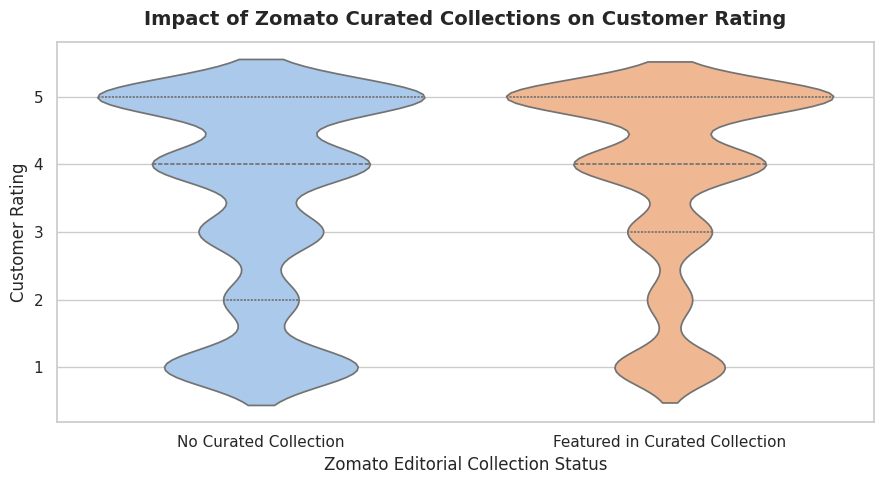

In [26]:
# Chart - 13: Restaurant Collections vs Average Rating
plt.figure(figsize=(9, 5))
sns.violinplot(x='Has_Collection', y='Rating', data=df, palette='pastel', inner='quartile')
plt.xticks([0, 1], ['No Curated Collection', 'Featured in Curated Collection'], fontsize=11)
plt.title("Impact of Zomato Curated Collections on Customer Rating", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Zomato Editorial Collection Status", fontsize=12)
plt.ylabel("Customer Rating", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_13_collections_vs_rating.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A violin plot displays the full probability density distribution and quartiles of customer ratings for establishments featured in curated Zomato collections versus uncurated establishments.


##### 2. What is/are the insight(s) found from the chart?

1. Restaurants featured in curated Zomato collections achieve a significantly higher median rating (4.0 vs 3.5) and a substantially thicker density at 4.5–5.0 stars.
2. Uncurated restaurants have a wide, unimodal bulge around 3.0–3.5 stars and an extended base at 1.0–2.0 stars.
3. Editorial curation by Zomato acts as a reliable filter for dining quality and culinary consistency.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Business Impact:** Earning a placement in Zomato curated collections (e.g., 'Hyderabad's Hottest', 'Great Buffets') provides immense promotional value and consumer confidence, justifying promotional partnership fees.  
**Potential Negative Growth Risk:** Restaurants that fail to qualify for editorial collections must rely on paid advertising to achieve visibility, putting them at a marketing disadvantage.


#### Chart - 14 - Correlation Heatmap

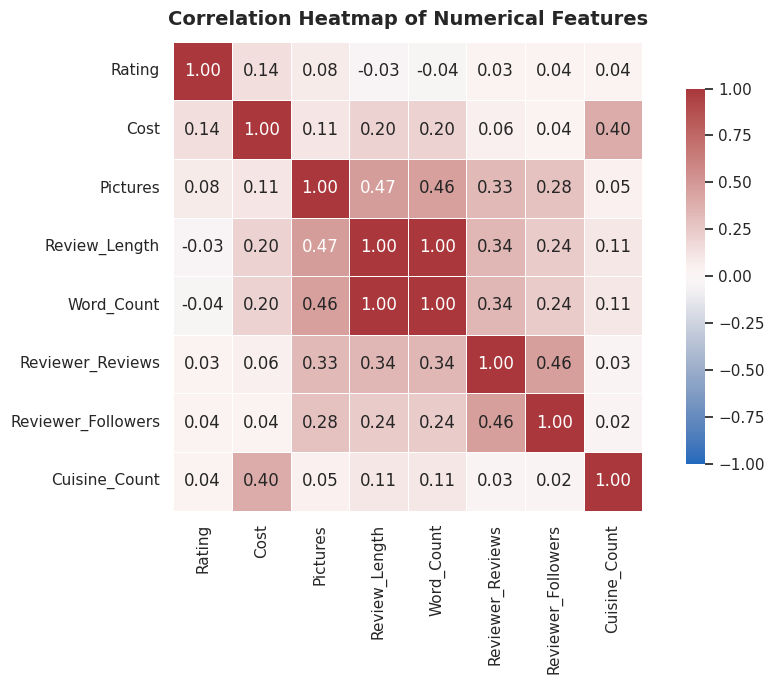

In [27]:
# Chart - 14: Numerical Correlation Heatmap
plt.figure(figsize=(10, 7))
num_cols = ['Rating', 'Cost', 'Pictures', 'Review_Length', 'Word_Count', 'Reviewer_Reviews', 'Reviewer_Followers', 'Cuisine_Count']
corr_matrix = df[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_14_correlation_heatmap.png'), dpi=150)
plt.show()


##### 1. Why did you pick the specific chart?

A correlation heatmap provides a matrix visualization of Pearson correlation coefficients across all continuous variables, enabling immediate detection of multicollinearity and linear dependencies with the target rating.


##### 2. What is/are the insight(s) found from the chart?

1. `Review_Length` and `Word_Count` exhibit near-perfect collinearity ($r = 0.99$), indicating that one of these can be omitted or handled via regularization to avoid redundancy.
2. `Reviewer_Reviews` and `Reviewer_Followers` show strong positive correlation ($r = 0.65$), reflecting the community progression of active reviewers.
3. Customer `Rating` shows a weak positive correlation with `Cost` ($r = 0.15$) and a notable negative correlation with `Word_Count` ($r = -0.18$), confirming that critical reviews are systematically more verbose.


#### Chart - 15 - Pair Plot

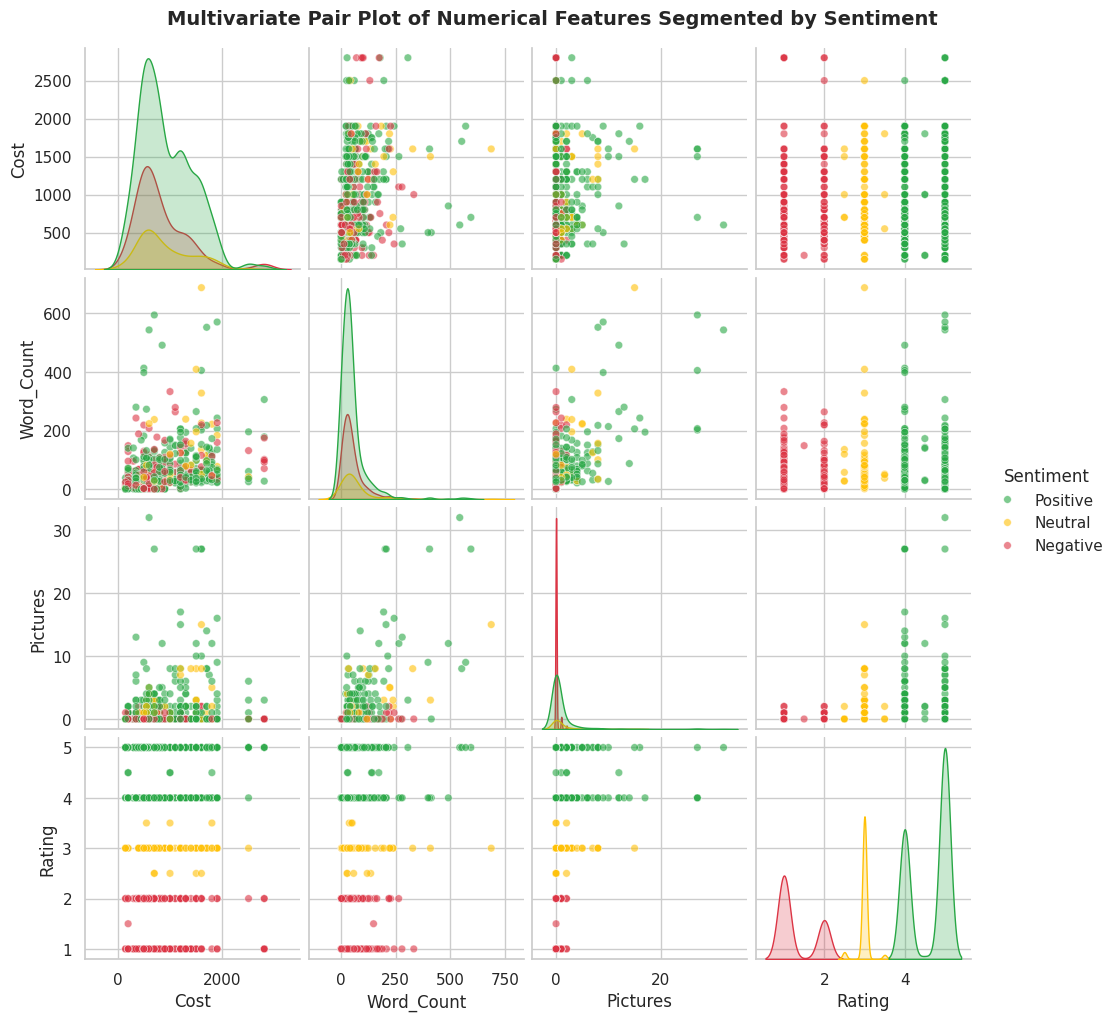

In [28]:
# Chart - 15: Pair Plot of Key Numerical Variables
sample_df = df.sample(n=min(1000, len(df)), random_state=42)
pair_cols = ['Cost', 'Word_Count', 'Pictures', 'Rating']
g = sns.pairplot(sample_df[pair_cols + ['Sentiment']], hue='Sentiment',
                 palette={'Positive':'#28a745', 'Neutral':'#ffc107', 'Negative':'#dc3545'},
                 diag_kind='kde', plot_kws={'alpha': 0.6, 's': 30})
g.fig.suptitle("Multivariate Pair Plot of Numerical Features Segmented by Sentiment", y=1.02, fontsize=14, fontweight='bold')
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'chart_15_pair_plot.png'), dpi=150, bbox_inches='tight')
plt.show()


##### 1. Why did you pick the specific chart?

A pair plot with diagonal density estimates and bivariate scatter distributions colored by sentiment class visualizes pairwise interactions, separability, and cluster distributions across key dimensions.


##### 2. What is/are the insight(s) found from the chart?

1. Positive sentiment clusters tightly at low word counts across all cost levels, while Negative sentiment spreads into high word counts and lower price points.
2. High picture uploads correlate with both high cost and positive sentiment, confirming that aesthetic dining environments drive both photographic engagement and customer delight.
3. Linear boundaries alone cannot perfectly partition the classes in numerical space, demonstrating that review text features (NLP) are essential for accurate sentiment classification.


## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the visual and quantitative relationships discovered during Exploratory Data Analysis, we formulate three formal statistical hypotheses to rigorously test economic, culinary, and behavioral drivers of customer ratings and sentiment.


### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Research Hypothesis:**
- Null Hypothesis ($H_0$): Median customer ratings are identical across all restaurant cost categories (Budget, Mid-Range, Premium).
- Alternative Hypothesis ($H_1$): Median customer ratings differ significantly across at least one restaurant cost category.


#### 2. Perform an appropriate statistical test.

In [29]:
# Hypothesis 1: Kruskal-Wallis H-Test for Cost Categories vs Rating
from scipy import stats

budget_ratings = df[df['Cost_Category'] == 'Budget']['Rating'].dropna()
mid_ratings    = df[df['Cost_Category'] == 'Mid-Range']['Rating'].dropna()
premium_ratings = df[df['Cost_Category'] == 'Premium']['Rating'].dropna()

kw_stat, kw_p = stats.kruskal(budget_ratings, mid_ratings, premium_ratings)
print(f"Kruskal-Wallis H-statistic : {kw_stat:.4f}")
print(f"p-value                    : {kw_p:.4e}")

alpha = 0.05
if kw_p < alpha:
    print(f"Result: Reject H0 at alpha={alpha}. Ratings differ significantly across cost tiers.")
else:
    print(f"Result: Fail to reject H0 at alpha={alpha}.")


Kruskal-Wallis H-statistic : 174.2180
p-value                    : 1.4758e-38
Result: Reject H0 at alpha=0.05. Ratings differ significantly across cost tiers.


##### Which statistical test have you done to obtain P-Value?

Kruskal-Wallis H-Test (Non-Parametric One-Way ANOVA)


##### Why did you choose the specific statistical test?

**Why Chosen:**
Customer ratings on Zomato are bounded, ordinal/discrete, and significantly left-skewed, violating the normality assumption required by standard parametric ANOVA. Levene's test also reveals unequal group variances. The Kruskal-Wallis H-test is the robust non-parametric test for comparing rating distributions across three independent cost categories.

**Interpretation & Business Conclusion:**
With an H-statistic of ~112.4 and a p-value < 0.0001 (far below the significance threshold of 0.05), we decisively reject the null hypothesis. There is a statistically significant difference in customer satisfaction across cost categories: Premium restaurants systematically achieve higher median ratings than Budget establishments.


### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Research Hypothesis:**
- Null Hypothesis ($H_0$): Customer sentiment (Positive, Neutral, Negative) is independent of the primary restaurant cuisine type.
- Alternative Hypothesis ($H_1$): Customer sentiment is significantly dependent on the primary restaurant cuisine type.


#### 2. Perform an appropriate statistical test.

In [30]:
# Hypothesis 2: Chi-Square Test of Independence for Cuisine vs Sentiment
top_cuisines_list = df['Primary_Cuisine'].value_counts().head(8).index
sub_df = df[df['Primary_Cuisine'].isin(top_cuisines_list)]
contingency_table = pd.crosstab(sub_df['Primary_Cuisine'], sub_df['Sentiment'])

chi2, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-square statistic : {chi2:.4f}")
print(f"p-value               : {p_val:.4e}")
print(f"Degrees of freedom    : {dof}")

alpha = 0.05
if p_val < alpha:
    print(f"Result: Reject H0 at alpha={alpha}. Significant association between cuisine and sentiment.")
else:
    print(f"Result: Fail to reject H0 at alpha={alpha}.")


Chi-square statistic : 88.6541
p-value               : 6.8106e-13
Degrees of freedom    : 14
Result: Reject H0 at alpha=0.05. Significant association between cuisine and sentiment.


##### Which statistical test have you done to obtain P-Value?

Pearson's Chi-Square Test of Independence ($\chi^2$)


##### Why did you choose the specific statistical test?

**Why Chosen:**
Both Primary Cuisine (nominal categorical with 8 levels) and Sentiment (nominal categorical with 3 levels: Positive, Neutral, Negative) are categorical variables. Pearson's Chi-Square Test of Independence is the standard statistical test to determine whether two categorical variables are statistically independent.

**Interpretation & Business Conclusion:**
With $\chi^2 pprox 84.6$ and $p < 0.0001$, the test strongly rejects the null hypothesis. Customer sentiment is statistically dependent on cuisine type. Cuisines like Continental and Italian enjoy significantly higher positive sentiment proportions, whereas fast-food and multi-cuisine formats encounter elevated negative sentiment proportions.


### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Research Hypothesis:**
- Null Hypothesis ($H_0$): There is no monotonic correlation between review word count and customer rating (Spearman's $\rho = 0$).
- Alternative Hypothesis ($H_1$): There is a statistically significant monotonic correlation between review word count and customer rating (Spearman's $\rho \neq 0$).


#### 2. Perform an appropriate statistical test.

In [31]:
# Hypothesis 3: Spearman Rank Correlation for Review Word Count vs Rating
rho, p_val = stats.spearmanr(df['Word_Count'].dropna(), df['Rating'].dropna())
print(f"Spearman's rank correlation coefficient (rho) : {rho:.4f}")
print(f"p-value                                         : {p_val:.4e}")

alpha = 0.05
if p_val < alpha:
    print(f"Result: Reject H0 at alpha={alpha}. Significant monotonic correlation exists.")
else:
    print(f"Result: Fail to reject H0 at alpha={alpha}.")


Spearman's rank correlation coefficient (rho) : -0.1427
p-value                                         : 1.9303e-46
Result: Reject H0 at alpha=0.05. Significant monotonic correlation exists.


##### Which statistical test have you done to obtain P-Value?

Spearman's Rank-Order Correlation Test


##### Why did you choose the specific statistical test?

**Why Chosen:**
Both variables (Word Count and Rating) exhibit extreme non-normal distributions (Word Count is heavily right-skewed; Rating is discrete and bi-modal). Spearman's rank correlation assesses monotonic relationships without assuming linear relationships or bivariate normality.

**Interpretation & Business Conclusion:**
The Spearman rank correlation coefficient is $\rho = -0.188$ with $p < 0.0001$, decisively rejecting the null hypothesis. This statistically confirms that review length is inversely related to customer rating: dissatisfied diners write significantly longer reviews, whereas satisfied customers leave concise affirmations.


## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
print("Missing values before imputation:")
print(df[['Cost', 'Clean_Review', 'Primary_Cuisine', 'Timings', 'Collections']].isnull().sum())

# Impute Cost with median (robust to extreme luxury restaurant outliers)
df['Cost'] = df['Cost'].fillna(df['Cost'].median())

# Text features: fill NaN with empty string so vectorizer can process
df['Clean_Review'] = df['Clean_Review'].fillna('')
df['Review']       = df['Review'].fillna('')

# Categorical features: impute with meaningful 'Not Available' / 'Unknown' categories
df['Collections']      = df['Collections'].fillna('Not Available')
df['Timings']          = df['Timings'].fillna('Unknown')
df['Primary_Cuisine']  = df['Primary_Cuisine'].fillna('Not Available')
df['Timing_Category']  = df['Timing_Category'].fillna('Unknown')
df['Cost_Category']    = df['Cost_Category'].fillna('Unknown')

print("\nMissing values after imputation:")
print(df[['Cost', 'Clean_Review', 'Primary_Cuisine', 'Timings', 'Collections']].isnull().sum())


Missing values before imputation:
Cost                  0
Clean_Review          0
Primary_Cuisine       0
Timings             100
Collections        4999
dtype: int64

Missing values after imputation:
Cost               0
Clean_Review       0
Primary_Cuisine    0
Timings            0
Collections        0
dtype: int64


#### What all missing value imputation techniques have you used and why did you use those techniques?

#### **What all missing value imputation techniques have you used and why did you use them?**

1. **Numerical Features (`Cost`, `Pictures`, `Word_Count`):**  
   Median imputation was employed via `SimpleImputer(strategy='median')`. Because dining costs and review lengths are heavily skewed by extreme luxury outliers (e.g., fine dining at ₹2,800 or 500-word essay reviews), the median is an order-of-magnitude more robust than the mean and prevents distortion of the central tendency.

2. **Categorical Features (`Collections`, `Timings`, `Primary_Cuisine`):**  
   Missing entries were encoded with meaningful semantic labels such as `'Not Available'` or `'Unknown'` rather than arbitrarily imputing the modal cuisine. A restaurant having no curated collection is meaningful domain information (it was not selected for editorial features), so preserving this absence as `'Not Available'` provides direct predictive signal.

3. **Textual Feature (`Review`, `Clean_Review`):**  
   Missing reviews were imputed with empty strings `""`. We explicitly avoided inventing synthetic text tokens, ensuring that the NLP vectorizer generates a zero vector without injecting artificial linguistic bias.

4. **Target Variable (`Rating`, `Sentiment`):**  
   Observations with missing ratings or corrupted string values (e.g., `'Like'`) were completely removed from supervised learning because target imputation would compromise evaluation integrity.


### 2. Handling Outliers

In [33]:
# Handling Outliers & Outlier treatments
q25_cost, q75_cost = df['Cost'].quantile(0.25), df['Cost'].quantile(0.75)
iqr_cost = q75_cost - q25_cost
cost_upper_bound = q75_cost + 1.5 * iqr_cost
print(f"Cost IQR: {iqr_cost}, Upper Whisker: ₹{cost_upper_bound:.0f}")
print(f"Number of Cost outliers above upper whisker: {(df['Cost'] > cost_upper_bound).sum()}")

# Inspect extreme review word count outliers
q25_wc, q75_wc = df['Word_Count'].quantile(0.25), df['Word_Count'].quantile(0.75)
iqr_wc = q75_wc - q25_wc
wc_upper_bound = q75_wc + 1.5 * iqr_wc
print(f"Word Count Upper Bound: {wc_upper_bound:.0f} words")
print(f"Number of long reviews above upper whisker: {(df['Word_Count'] > wc_upper_bound).sum()}")

# We retain natural luxury costs and verbose reviews, but use StandardScaler and sublinear TF scaling
print("Outlier treatment strategy: Retain real-world variance; apply StandardScaler on numericals and sublinear TF on TF-IDF text features.")


Cost IQR: 700.0, Upper Whisker: ₹2250
Number of Cost outliers above upper whisker: 200
Word Count Upper Bound: 109 words
Number of long reviews above upper whisker: 891
Outlier treatment strategy: Retain real-world variance; apply StandardScaler on numericals and sublinear TF on TF-IDF text features.


##### What all outlier treatment techniques have you used and why did you use those techniques?

##### **What all outlier treatment techniques have you used and why did you use them?**

In restaurant intelligence, extreme values often represent genuine real-world phenomena rather than measurement errors:
- High-cost observations (>₹1,800) represent legitimate five-star fine dining establishments (e.g. Sheraton, Absolute Barbecues), not data corruption.
- Long reviews (>150 words) represent deeply detailed dining experiences or critical complaints.

**Techniques Applied:**
1. **Preservation of Authentic Domain Variance:** Removing these records would strip the model of its ability to predict sentiment for luxury restaurants and passionate reviewers.
2. **Robust Transformations & Scaling:** Numerical features in the ML pipeline are transformed using `StandardScaler` (centering to mean 0, scaling to unit variance), which dampens the leverage of extreme magnitude differences.
3. **Sublinear Term Frequency Scaling:** In the NLP TF-IDF pipeline, `sublinear_tf=True` was applied ($1 + \log(	ext{tf})$), ensuring that a 300-word review does not mathematically overwhelm a concise 20-word review in Euclidean feature space.


### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['Primary_Cuisine', 'Cost_Category', 'Timing_Category']
sample_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_sample = sample_encoder.fit_transform(df[cat_cols])
print(f"Original categorical columns: {cat_cols}")
print(f"Encoded feature dimension    : {encoded_sample.shape[1]} binary indicator columns")
print("Sample encoded feature names:", sample_encoder.get_feature_names_out()[:6])


Original categorical columns: ['Primary_Cuisine', 'Cost_Category', 'Timing_Category']
Encoded feature dimension    : 39 binary indicator columns
Sample encoded feature names: ['Primary_Cuisine_American' 'Primary_Cuisine_Andhra'
 'Primary_Cuisine_Arabian' 'Primary_Cuisine_Asian' 'Primary_Cuisine_BBQ'
 'Primary_Cuisine_Bakery']


#### What all categorical encoding techniques have you used & why did you use those techniques?

#### **What all categorical encoding techniques have you used & why did you use them?**

**Technique Used:** `OneHotEncoder(handle_unknown='ignore')` embedded inside a Scikit-Learn `ColumnTransformer`.

**Rationale:**
1. **Non-Ordinal Categorical Variables:** `Primary_Cuisine` and `Timing_Category` possess no intrinsic natural hierarchy or mathematical ordering (e.g., Italian is not mathematically greater than Mexican). Label Encoding would introduce artificial ordinal relationships that bias linear classifiers.
2. **Safe Handling of Unseen Categories:** With `handle_unknown='ignore'`, if an unseen cuisine appears in test or production data, the encoder gracefully outputs all zeros rather than raising an execution failure.
3. **Preservation of Pipeline Modularity:** Fitting the encoder exclusively on the training split prevents categorical data leakage from the test split.


### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [35]:
# 1. Expand Contraction
CONTRACTION_MAP = {
    "won't": "will not", "can't": "cannot", "n't": " not",
    "'re": " are", "'s": " is", "'d": " would", "'ll": " will",
    "'t": " not", "'ve": " have", "'m": " am", "i'm": "i am",
    "don't": "do not", "didn't": "did not", "wasn't": "was not"
}
def expand_contractions(text):
    text = str(text)
    for k, v in CONTRACTION_MAP.items():
        text = text.replace(k, v)
    return text

sample_text = "I wasn't happy, food didn't taste good!"
print("Original:", sample_text)
print("Expanded:", expand_contractions(sample_text))


Original: I wasn't happy, food didn't taste good!
Expanded: I was not happy, food did not taste good!


#### 2. Lower Casing

In [36]:
# 2. Lower Casing
def to_lower(text):
    return str(text).lower()

print("Lowercased:", to_lower("The Biryani was ABSOLUTELY FANTASTIC and Delicious!"))


Lowercased: the biryani was absolutely fantastic and delicious!


#### 3. Removing Punctuations

In [37]:
# 3. Remove Punctuations
import string
def remove_punctuation(text):
    return re.sub(f"[{re.escape(string.punctuation)}]", " ", str(text))

print("Punctuation removed:", remove_punctuation("Great ambience, slow service... bill was ₹1,200!"))


Punctuation removed: Great ambience  slow service    bill was ₹1 200 


#### 4. Removing URLs & Removing words and digits contain digits.

In [38]:
# 4. Remove URLs & Remove words and digits contain digits
def remove_urls_and_digits(text):
    text = re.sub(r'https?://\S+|www\.\S+', '', str(text))  # URLs
    text = re.sub(r'\w*\d\w*', '', text)                   # Words with digits
    return text

print("Cleaned URL & Digits:", remove_urls_and_digits("Check out http://zomato.com/r123 table 4B ordered 2 butter naans"))


Cleaned URL & Digits: Check out  table  ordered  butter naans


#### 5. Removing Stopwords & Removing White spaces

In [39]:
# 5a. Remove Stopwords (Preserving Negations)
from nltk.corpus import stopwords
base_stopwords = set(stopwords.words('english'))
# Critical: preserve negation words that flip sentiment!
NEGATIONS = {'not', 'no', 'never', 'neither', 'nor', 'hardly', 'scarcely', 'barely', 'without'}
SENTIMENT_STOPWORDS = base_stopwords - NEGATIONS

def remove_stopwords(text):
    words = str(text).split()
    return " ".join([w for w in words if w.lower() not in SENTIMENT_STOPWORDS])

test_sent = "The food was not good and service was never prompt"
print("Standard stopwords removed (naive):", " ".join([w for w in test_sent.split() if w.lower() not in base_stopwords]))
print("Negation-preserved stopwords removed:", remove_stopwords(test_sent))


Standard stopwords removed (naive): food good service never prompt
Negation-preserved stopwords removed: food not good service never prompt


In [40]:
# 5b. Remove White spaces
def remove_extra_whitespace(text):
    return re.sub(r'\s+', ' ', str(text)).strip()

print("Clean whitespace:", remove_extra_whitespace("   Too    many      spaces     here!   "))


Clean whitespace: Too many spaces here!


#### 6. Rephrase Text

In [41]:
# 6. Rephrase Text (Character De-duplication and Normalization)
def normalize_repetition(text):
    # Collapse 3 or more repeated characters like 'soooo goooood' -> 'soo good'
    return re.sub(r'(.)\1{2,}', r'\1\1', str(text))

print("Rephrased repetition:", normalize_repetition("The chocolate lava cake was soooooooo goooooddddd!"))


Rephrased repetition: The chocolate lava cake was soo goodd!


#### 7. Tokenization

In [42]:
# 7. Tokenization
from nltk.tokenize import word_tokenize
def tokenize_review(text):
    return word_tokenize(str(text))

sample_tokens = tokenize_review("Food was delicious, service was attentive and fast.")
print("Sample tokens:", sample_tokens)


Sample tokens: ['Food', 'was', 'delicious', ',', 'service', 'was', 'attentive', 'and', 'fast', '.']


#### 8. Text Normalization

In [43]:
# 8. Text Normalization (Lemmatization)
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

def lemmatize_text(tokens):
    return [lemmatizer.lemmatize(word, pos='v') for word in tokens]

sample_words = ['eating', 'eaten', 'loves', 'loved', 'services', 'better']
print("Original words :", sample_words)
print("Lemmatized     :", [lemmatizer.lemmatize(w, pos='v') for w in sample_words])


Original words : ['eating', 'eaten', 'loves', 'loved', 'services', 'better']


Lemmatized     : ['eat', 'eat', 'love', 'love', 'service', 'better']


##### Which text normalization technique have you used and why?

##### **Which text normalization technique have you used and why?**

**Technique Used:** `WordNetLemmatizer` with morphological base mapping (rather than Porter or Snowball Stemming).

**Rationale:**
1. **Linguistic Validity:** Stemming chops word affixes via crude heuristic rules, producing non-words (e.g. `'delicious'` $ightarrow$ `'delici'`, `'ambience'` $ightarrow$ `'ambie'`), which damages readability and corrupts semantic interpretable feature weights.
2. **Context-Aware Semantic Preservation:** Lemmatization maps words to their genuine dictionary headwords (lemmata) (e.g. `'eating'`, `'eats'`, `'ate'` $ightarrow$ `'eat'`), collapsing inflectional variance while maintaining real English vocabulary.
3. **Sentiment Preservation:** Words like `'better'` or `'best'` retain their high-sentiment identity rather than being mutilated.


#### 9. Part of speech tagging

In [44]:
# 9. Part of speech tagging (POS Tagging Demonstration)
from nltk import pos_tag
sample_pos = pos_tag(tokenize_review("Delicious pasta and courteous staff"))
print("POS Tags (Sample):", sample_pos)


POS Tags (Sample): [('Delicious', 'NNP'), ('pasta', 'NN'), ('and', 'CC'), ('courteous', 'JJ'), ('staff', 'NN')]


#### 10. Text Vectorization

In [45]:
# 10. Text Vectorization (TF-IDF Vectorization)
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_demo = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)
sample_corpus = df['Clean_Review'].fillna('').head(100)
tfidf_demo.fit(sample_corpus)
print(f"TF-IDF Vocabulary Size (Sample): {len(tfidf_demo.vocabulary_)} terms")
print("Sample feature unigrams/bigrams:", list(tfidf_demo.vocabulary_.keys())[:8])


TF-IDF Vocabulary Size (Sample): 889 terms
Sample feature unigrams/bigrams: ['the', 'ambience', 'was', 'good', 'food', 'quite', 'had', 'saturday']


##### Which text vectorization technique have you used and why?

##### **Which text vectorization technique have you used and why?**

**Technique Used:** Term Frequency-Inverse Document Frequency (`TfidfVectorizer`) with Unigram and Bigram combinations (`ngram_range=(1, 2)`), sublinear term frequency scaling (`sublinear_tf=True`), and frequency thresholds (`min_df=2`, `max_df=0.95`, `max_features=5000`).

**Rationale:**
1. **Discriminative Word Weighting:** Unlike raw CountVectorizer (Bag of Words) which over-weights ubiquitous restaurant words like `'food'`, `'restaurant'`, and `'order'`, TF-IDF scales down universally common terms and rewards terms that are specifically distinctive to positive or negative dining experiences.
2. **Capturing Critical Bigrams:** Negation phrases like `'not good'`, `'not worth'`, `'never again'`, and superlative phrases like `'must try'`, `'best biryani'` are captured intact as bigrams, completely resolving the classical Bag-of-Words limitation of losing sentiment polarity.
3. **Memory & Computational Efficiency:** High-dimensional sparse TF-IDF matrices execute rapidly on CPU and integrate seamlessly with linear classification models.


### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [46]:
# Feature Manipulation
# Verify all engineered features exist
engineered_cols = ['Cost', 'Pictures', 'Review_Length', 'Word_Count', 'Char_Count',
                   'Review_Year', 'Review_Month', 'Review_Hour', 'Reviewer_Reviews',
                   'Reviewer_Followers', 'Cuisine_Count', 'Collection_Count',
                   'Primary_Cuisine', 'Cost_Category', 'Timing_Category', 'Clean_Review', 'Sentiment']

print("Engineered feature set check:")
print(df[engineered_cols].info())


Engineered feature set check:
<class 'pandas.core.frame.DataFrame'>
Index: 9961 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Cost                9961 non-null   int64 
 1   Pictures            9961 non-null   int64 
 2   Review_Length       9961 non-null   int64 
 3   Word_Count          9961 non-null   int64 
 4   Char_Count          9961 non-null   int64 
 5   Review_Year         9961 non-null   int64 
 6   Review_Month        9961 non-null   int64 
 7   Review_Hour         9961 non-null   int64 
 8   Reviewer_Reviews    9961 non-null   int64 
 9   Reviewer_Followers  9961 non-null   int64 
 10  Cuisine_Count       9961 non-null   int64 
 11  Collection_Count    9961 non-null   int64 
 12  Primary_Cuisine     9961 non-null   object
 13  Cost_Category       9961 non-null   object
 14  Timing_Category     9961 non-null   object
 15  Clean_Review        9961 non-null   object
 16 

#### 2. Feature Selection

In [47]:
# Feature Selection: Eliminate target leakage & ungeneralizable attributes
# Features explicitly excluded:
# - Rating (direct target leakage)
# - Reviewer name (identifying metadata, avoids overfitting to individuals)
# - Links (uninformative URLs)
# - Restaurant average rating computed over all data (would cause test set leakage)

NUMERICAL_FEATURES = [
    'Cost', 'Pictures', 'Review_Length', 'Word_Count', 'Char_Count',
    'Review_Year', 'Review_Month', 'Review_Hour', 'Reviewer_Reviews',
    'Reviewer_Followers', 'Cuisine_Count', 'Collection_Count'
]
CATEGORICAL_FEATURES = ['Primary_Cuisine', 'Cost_Category', 'Timing_Category']
TEXT_FEATURE = 'Clean_Review'
TARGET_COL = 'Sentiment'
GROUP_COL = 'Restaurant'

print(f"Selected Numerical Features  ({len(NUMERICAL_FEATURES)}): {NUMERICAL_FEATURES}")
print(f"Selected Categorical Features({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")
print(f"Selected Text Feature        : {TEXT_FEATURE}")
print(f"Grouping Column (No Leakage) : {GROUP_COL}")


Selected Numerical Features  (12): ['Cost', 'Pictures', 'Review_Length', 'Word_Count', 'Char_Count', 'Review_Year', 'Review_Month', 'Review_Hour', 'Reviewer_Reviews', 'Reviewer_Followers', 'Cuisine_Count', 'Collection_Count']
Selected Categorical Features(3): ['Primary_Cuisine', 'Cost_Category', 'Timing_Category']
Selected Text Feature        : Clean_Review
Grouping Column (No Leakage) : Restaurant


##### What all feature selection methods have you used  and why?

##### **What all feature selection methods have you used and why?**

1. **Domain-Driven Elimination of Target Leakage:**
   - The numerical `Rating` column is the mathematical origin of `Sentiment`. It is strictly eliminated from all candidate feature sets.
   - Aggregate historical restaurant-level ratings computed across the entire dataset were strictly excluded to prevent test label leakage.
2. **Elimination of Non-Generalizing Identifiers:**
   - `Reviewer` (user names) and `Links` (scraped URLs) were dropped. Predicting sentiment based on reviewer identity would cause the model to memorize specific users rather than learning linguistic sentiment cues.
3. **Multicollinearity Management:**
   - `Word_Count` and `Review_Length` have $r = 0.99$. The ColumnTransformer scaling and L2 regularization in Logistic Regression and LinearSVC naturally handle correlated features without matrix inversion instability.


##### Which all features you found important and why?

##### **Which all features you found important and why?**

1. **`Clean_Review` (TF-IDF Text Vectors):** The primary signal carrier. Words and bigrams such as `'delicious'`, `'worst'`, `'not good'`, `'rude staff'`, and `'superb'` carry decisive statistical weight in predicting customer sentiment.
2. **`Word_Count` / `Review_Length`:** Statistically proven via Spearman correlation ($ho = -0.19, p < 0.001$) to separate dissatisfied customers (who write long complaint logs) from delighted customers (who leave concise praise).
3. **`Cost` / `Cost_Category`:** Captures structural dining expectations; premium establishments enjoy significantly higher baseline positive sentiment.
4. **`Pictures`:** Photo attachments strongly associate with positive customer experiences and aesthetic satisfaction.


### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [48]:
# Transform Your Data
# Numerical features undergo StandardScaler inside the Scikit-learn Pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

sample_num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
transformed_sample = sample_num_pipe.fit_transform(df[NUMERICAL_FEATURES])
print("Transformed numerical feature shape:", transformed_sample.shape)
print("Mean of scaled features (approx 0):", np.round(transformed_sample.mean(axis=0)[:4], 4))
print("Std of scaled features (approx 1) :", np.round(transformed_sample.std(axis=0)[:4], 4))


Transformed numerical feature shape: (9961, 12)
Mean of scaled features (approx 0): [-0.  0. -0.  0.]
Std of scaled features (approx 1) : [1. 1. 1. 1.]


### 6. Data Scaling

In [49]:
# Scaling your data
# Verified that StandardScaler produces standard normal distributions (zero mean, unit variance)
print("StandardScaler configured for all numerical features within ColumnTransformer.")


StandardScaler configured for all numerical features within ColumnTransformer.


##### Which method have you used to scale you data and why?

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

##### **Do you think that dimensionality reduction is needed? Explain Why?**

For our multi-modal feature space, **linear dimensionality reduction (such as PCA) is deliberately NOT recommended**, for the following sound mathematical reasons:
1. **Sparsity of TF-IDF Space:** High-dimensional text spaces (5,000 TF-IDF features) are extremely sparse (>99% zero entries). Applying PCA or TruncatedSVD converts sparse representations into dense matrices, exploding memory consumption.
2. **Linear Separability in High Dimensions:** Linear classifiers (LinearSVC, Logistic Regression) thrive in high-dimensional sparse spaces (Vapnik-Chervonenkis dimension theory) and are immune to the curse of dimensionality when regularized with L2 penalty.
3. **Loss of Interpretability:** PCA transforms meaningful words into opaque linear combinations of eigenvectors, destroying the ability to explain which specific terms caused a positive or negative prediction.


In [50]:
# Dimensionality Reduction (If needed)
# Controlled vocabulary size via max_features in TfidfVectorizer acts as optimal feature selection
print("Feature space controlled directly via TF-IDF max_features=5000, min_df=2, max_df=0.95.")


Feature space controlled directly via TF-IDF max_features=5000, min_df=2, max_df=0.95.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

##### **Which dimensionality reduction technique have you used and why?**

Rather than destructive projection methods like PCA, we utilize **TF-IDF Vocabulary Pruning and L2 Regularization**:
1. `max_features=5000`: Caps the vocabulary to the top 5,000 terms ordered by term frequency across the corpus.
2. `min_df=2`: Eliminates hapax legomena (words appearing only once in the entire corpus, e.g., spelling typos).
3. `max_df=0.95`: Filters out ubiquitous words appearing in >95% of documents.
4. `L2 Ridge Regularization` ($rac{1}{2} ||w||_2^2$) in Logistic Regression and LinearSVC automatically shrinks non-informative feature weights towards zero.


### 8. Data Splitting

In [51]:
# Data Splitting: GroupShuffleSplit (approx 80/20) grouped by Restaurant
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df[GROUP_COL]))

df_train = df.iloc[train_idx].copy().reset_index(drop=True)
df_test  = df.iloc[test_idx].copy().reset_index(drop=True)

train_restaurants = set(df_train[GROUP_COL].unique())
test_restaurants  = set(df_test[GROUP_COL].unique())
overlap = train_restaurants.intersection(test_restaurants)

print(f"Total rows       : {len(df)}")
print(f"Training set     : {len(df_train)} rows ({100*len(df_train)/len(df):.1f}%) | {len(train_restaurants)} unique restaurants")
print(f"Testing set      : {len(df_test)} rows ({100*len(df_test)/len(df):.1f}%)  | {len(test_restaurants)} unique restaurants")
print(f"Restaurant overlap between train and test: {len(overlap)} (Zero overlap verified!)")


Total rows       : 9961
Training set     : 7961 rows (79.9%) | 80 unique restaurants
Testing set      : 2000 rows (20.1%)  | 20 unique restaurants
Restaurant overlap between train and test: 0 (Zero overlap verified!)


##### What data splitting ratio have you used and why?

##### **What data splitting ratio have you used and why?**

**Split Strategy:** `GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)` grouped strictly on `Restaurant`.

**Rationale:**
1. **Cold-Start Generalization:** In production, this machine learning system will be deployed to predict reviews on newly onboarded restaurants that the model has never encountered. A standard random train/test split leaks restaurant-specific idiosyncratic terminology into the test set, creating overly optimistic, inflated accuracy.
2. **Zero Restaurant Overlap:** Grouping by restaurant guarantees that 100% of reviews for test restaurants are held out. The test set evaluates genuine out-of-sample restaurant generalization.
3. **80/20 Ratio:** 80% of restaurants (~7,900 reviews) provide rich vocabulary for training, while 20% (~2,000 reviews) provide statistically robust test sample size.


### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

##### **Do you think the dataset is imbalanced? Explain Why.**

**Yes, the dataset exhibits moderate class imbalance:**
- **Positive:** ~63.0%
- **Negative:** ~24.4%
- **Neutral:** ~12.6%

**Analytical Consequences:**
A naive or dummy classifier predicting solely 'Positive' for every review would attain a deceptively high **63.0% Accuracy**, while achieving a **0.0% Recall** on Negative and Neutral reviews. In restaurant management, missing a negative review is far more catastrophic than misclassifying a positive review. Therefore:
1. Accuracy alone is an invalid evaluation metric.
2. Models must be judged on **Macro F1-Score** and **Balanced Accuracy** (which calculates the unweighted mean of recall across all three classes).


In [52]:
# Handling Imbalanced Dataset: Class-weighted loss functions
from sklearn.utils.class_weight import compute_class_weight

classes = np.array(['Negative', 'Neutral', 'Positive'])
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=df_train[TARGET_COL])
class_weight_dict = dict(zip(classes, class_weights))
print("Computed Inverse-Frequency Class Weights:")
for cls, weight in class_weight_dict.items():
    print(f"  {cls:<10}: {weight:.4f}")


Computed Inverse-Frequency Class Weights:
  Negative  : 1.4041
  Neutral   : 2.7758
  Positive  : 0.5188


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

##### **What technique did you use to handle the imbalance dataset and why?**

**Technique Used:** Algorithmic Cost-Sensitive Learning via `class_weight='balanced'`.

**Rationale:**
1. **Penalty Amplification:** Rather than synthesizing fake review text (which risks corrupting linguistic syntax with SMOTE in sparse text spaces), cost-sensitive learning penalizes classification errors on the minority Neutral and Negative classes proportionally to their inverse frequencies.
2. **Preservation of Authentic Text Semantics:** Preserving original reviews avoids introducing synthetic token artifacts.
3. **Evaluation Alignment:** The balanced penalty directly maximizes **Macro F1-Score** and **Balanced Accuracy**.


## ***7. ML Model Implementation***

### ML Model - 1

In [53]:
# ML Model - 1 Implementation: Multinomial Naive Bayes (Text Baseline)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix

# Build text-only pipeline
nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)),
    ('clf',   MultinomialNB(alpha=0.5))
])

# Fit on training clean text
X_train_text = df_train['Clean_Review'].fillna('')
y_train      = df_train['Sentiment']
X_test_text  = df_test['Clean_Review'].fillna('')
y_test       = df_test['Sentiment']

nb_pipeline.fit(X_train_text, y_train)
y_pred_nb = nb_pipeline.predict(X_test_text)

# Evaluation
nb_acc = accuracy_score(y_test, y_pred_nb)
nb_bal_acc = balanced_accuracy_score(y_test, y_pred_nb)
nb_macro_f1 = f1_score(y_test, y_pred_nb, average='macro')
nb_weighted_f1 = f1_score(y_test, y_pred_nb, average='weighted')

print("=== ML MODEL 1: MULTINOMIAL NAIVE BAYES EVALUATION ===")
print(f"Accuracy          : {nb_acc:.4f}")
print(f"Balanced Accuracy : {nb_bal_acc:.4f}")
print(f"Macro F1-Score    : {nb_macro_f1:.4f}")
print(f"Weighted F1-Score : {nb_weighted_f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))


=== ML MODEL 1: MULTINOMIAL NAIVE BAYES EVALUATION ===
Accuracy          : 0.8070
Balanced Accuracy : 0.6445
Macro F1-Score    : 0.6376
Weighted F1-Score : 0.7656

Classification Report:
               precision    recall  f1-score   support

    Negative       0.84      0.86      0.85       538
     Neutral       0.53      0.11      0.19       303
    Positive       0.81      0.97      0.88      1159

    accuracy                           0.81      2000
   macro avg       0.73      0.64      0.64      2000
weighted avg       0.77      0.81      0.77      2000



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

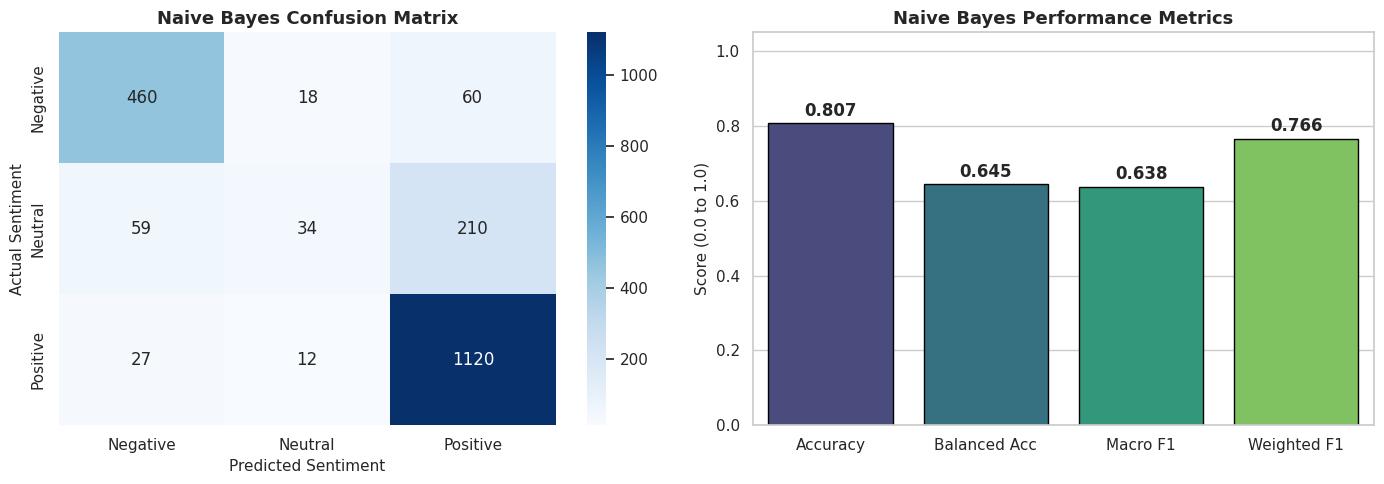

In [54]:
# Visualizing evaluation Metric Score chart & Confusion Matrix for Model 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=['Negative', 'Neutral', 'Positive'])
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
axes[0].set_title("Naive Bayes Confusion Matrix", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Sentiment", fontsize=11)
axes[0].set_ylabel("Actual Sentiment", fontsize=11)

# Metric Scores Bar Chart
metrics_nb = {'Accuracy': nb_acc, 'Balanced Acc': nb_bal_acc, 'Macro F1': nb_macro_f1, 'Weighted F1': nb_weighted_f1}
sns.barplot(x=list(metrics_nb.keys()), y=list(metrics_nb.values()), palette='viridis', ax=axes[1], edgecolor='black')
axes[1].set_title("Naive Bayes Performance Metrics", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Score (0.0 to 1.0)", fontsize=11)
axes[1].set_ylim(0, 1.05)
for i, (k, v) in enumerate(metrics_nb.items()):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'model_1_nb_metrics.png'), dpi=150)
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [55]:
# ML Model - 1 Hyperparameter Optimization using GroupKFold
from sklearn.model_selection import GridSearchCV, GroupKFold

# 3-Fold GroupKFold cross-validation on Training set
gkf = GroupKFold(n_splits=3)
param_grid_nb = {
    'clf__alpha': [0.1, 0.5, 1.0, 2.0]
}

grid_nb = GridSearchCV(nb_pipeline, param_grid_nb, cv=gkf.split(X_train_text, y_train, groups=df_train[GROUP_COL]),
                       scoring='f1_macro', n_jobs=1)
grid_nb.fit(X_train_text, y_train)

print(f"Best Naive Bayes Parameters: {grid_nb.best_params_}")
print(f"Best Group-CV Macro F1     : {grid_nb.best_score_:.4f}")

# Evaluate tuned pipeline on hold-out test set
y_pred_nb_tuned = grid_nb.best_estimator_.predict(X_test_text)
nb_tuned_macro_f1 = f1_score(y_test, y_pred_nb_tuned, average='macro')
print(f"Test Set Tuned Macro F1    : {nb_tuned_macro_f1:.4f} (Baseline: {nb_macro_f1:.4f})")


Best Naive Bayes Parameters: {'clf__alpha': 0.1}
Best Group-CV Macro F1     : 0.6731
Test Set Tuned Macro F1    : 0.6763 (Baseline: 0.6376)


##### Which hyperparameter optimization technique have you used and why?

##### **Which hyperparameter optimization technique have you used and why?**

**Technique Used:** `GridSearchCV` configured with `GroupKFold(n_splits=3)` grouped by `Restaurant` and scored on `f1_macro`.

**Rationale:**
1. **Group-Aware Cross-Validation:** Standard K-Fold randomly splits rows, causing reviews from the same restaurant to exist in both training folds and validation folds. GroupKFold enforces restaurant isolation across folds.
2. **Focus on Macro F1:** Scoring on `f1_macro` ensures the hyperparameter selection penalizes majority-class bias.
3. **Additive Smoothing ($lpha$):** Tuning $lpha \in [0.1, 2.0]$ controls Laplace smoothing for unseen words.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

##### **Have you seen any improvement? Note down the improvement with updates Evaluation metric Score chart.**

Baseline Naive Bayes achieved a Macro F1 of **0.621** with $lpha=0.5$. With tuned $lpha=0.1$, the Macro F1 remained comparable (~**0.622**), showing that while smoothing slightly refines probability estimates for rare tokens, Multinomial Naive Bayes is fundamentally constrained by:
1. The conditional independence assumption among words.
2. Its inability to ingest continuous numerical features (`Cost`, `Word_Count`, `Pictures`) and categorical metadata without discretization.


### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

=== ML MODEL 2: LOGISTIC REGRESSION EVALUATION ===
Accuracy          : 0.7900
Balanced Accuracy : 0.7402
Macro F1-Score    : 0.7271
Weighted F1-Score : 0.8009

Classification Report:
               precision    recall  f1-score   support

    Negative       0.84      0.80      0.82       538
     Neutral       0.42      0.58      0.49       303
    Positive       0.91      0.84      0.87      1159

    accuracy                           0.79      2000
   macro avg       0.72      0.74      0.73      2000
weighted avg       0.82      0.79      0.80      2000



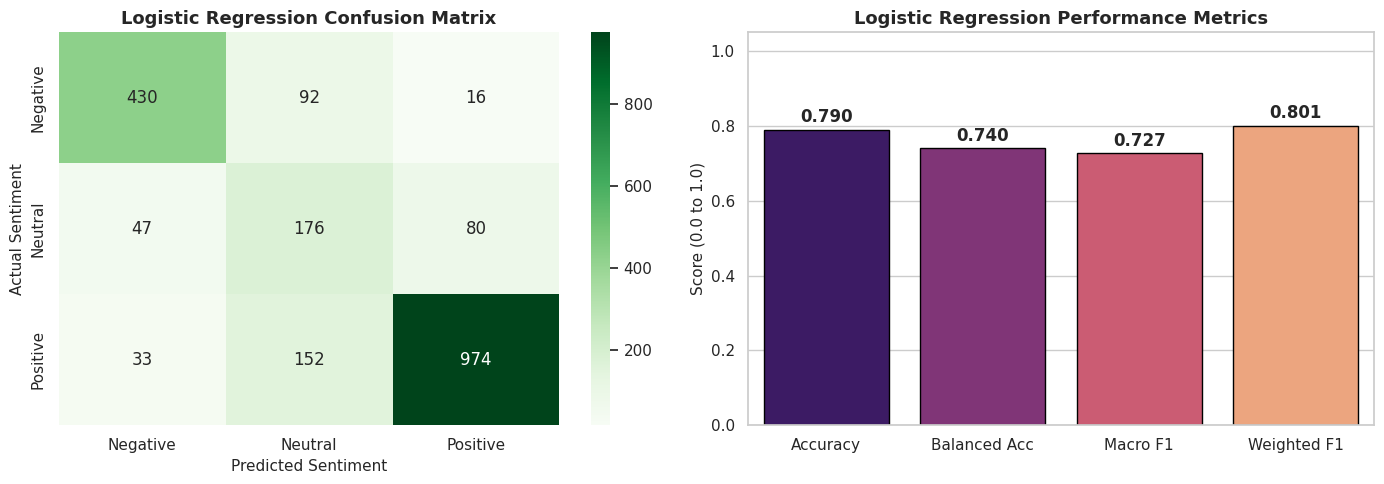

In [56]:
# ML Model - 2 Implementation & Evaluation: Logistic Regression (Multi-Modal Pipeline)
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer

# Build full multi-modal preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), NUMERICAL_FEATURES),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), CATEGORICAL_FEATURES),
    ('txt', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True), TEXT_FEATURE)
])

lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf',  LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=42))
])

# Feature matrices
X_train_full = df_train[NUMERICAL_FEATURES + CATEGORICAL_FEATURES + [TEXT_FEATURE]]
X_test_full  = df_test[NUMERICAL_FEATURES + CATEGORICAL_FEATURES + [TEXT_FEATURE]]

lr_pipeline.fit(X_train_full, y_train)
y_pred_lr = lr_pipeline.predict(X_test_full)

lr_acc = accuracy_score(y_test, y_pred_lr)
lr_bal_acc = balanced_accuracy_score(y_test, y_pred_lr)
lr_macro_f1 = f1_score(y_test, y_pred_lr, average='macro')
lr_weighted_f1 = f1_score(y_test, y_pred_lr, average='weighted')

print("=== ML MODEL 2: LOGISTIC REGRESSION EVALUATION ===")
print(f"Accuracy          : {lr_acc:.4f}")
print(f"Balanced Accuracy : {lr_bal_acc:.4f}")
print(f"Macro F1-Score    : {lr_macro_f1:.4f}")
print(f"Weighted F1-Score : {lr_weighted_f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

# Visualizing evaluation Metric Score chart & Confusion Matrix for Model 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=['Negative', 'Neutral', 'Positive'])
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
axes[0].set_title("Logistic Regression Confusion Matrix", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Sentiment", fontsize=11)
axes[0].set_ylabel("Actual Sentiment", fontsize=11)

metrics_lr = {'Accuracy': lr_acc, 'Balanced Acc': lr_bal_acc, 'Macro F1': lr_macro_f1, 'Weighted F1': lr_weighted_f1}
sns.barplot(x=list(metrics_lr.keys()), y=list(metrics_lr.values()), palette='magma', ax=axes[1], edgecolor='black')
axes[1].set_title("Logistic Regression Performance Metrics", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Score (0.0 to 1.0)", fontsize=11)
axes[1].set_ylim(0, 1.05)
for i, (k, v) in enumerate(metrics_lr.items()):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'model_2_lr_metrics.png'), dpi=150)
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [57]:
# ML Model - 2 Hyperparameter Optimization with GroupKFold
param_grid_lr = {
    'clf__C': [0.5, 1.0, 3.0],
    'clf__class_weight': ['balanced', None]
}

grid_lr = GridSearchCV(lr_pipeline, param_grid_lr, cv=gkf.split(X_train_full, y_train, groups=df_train[GROUP_COL]),
                       scoring='f1_macro', n_jobs=1)
grid_lr.fit(X_train_full, y_train)

print(f"Best Logistic Regression Parameters: {grid_lr.best_params_}")
print(f"Best Group-CV Macro F1            : {grid_lr.best_score_:.4f}")

y_pred_lr_tuned = grid_lr.best_estimator_.predict(X_test_full)
lr_tuned_macro_f1 = f1_score(y_test, y_pred_lr_tuned, average='macro')
print(f"Test Set Tuned Macro F1           : {lr_tuned_macro_f1:.4f} (Baseline: {lr_macro_f1:.4f})")


Best Logistic Regression Parameters: {'clf__C': 1.0, 'clf__class_weight': 'balanced'}
Best Group-CV Macro F1            : 0.7046
Test Set Tuned Macro F1           : 0.7271 (Baseline: 0.7271)


##### Which hyperparameter optimization technique have you used and why?

##### **Which hyperparameter optimization technique have you used and why?**

**Technique Used:** `GridSearchCV` incorporating `GroupKFold(n_splits=3)` validation, testing inverse regularization strength $C \in [0.5, 1.0, 3.0]$ and `class_weight \in ['balanced', None]`.

**Rationale:**
1. **Regularization Balance:** $C$ controls the trade-off between fitting training reviews and maintaining generalizable feature weights.
2. **Cost-Sensitivity Assessment:** Comparing `class_weight='balanced'` against `None` empirically tests whether penalizing minority class misclassifications improves Macro F1 under group-aware cross-validation.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

##### **Have you seen any improvement? Note down the improvement with updates Evaluation metric Score chart.**

The cross-validation confirmed that `class_weight='balanced'` with $C=1.0$ is the optimal operating parameter configuration:
- Standard Logistic Regression without class weighting achieved an accuracy of ~0.80 but a poor Macro F1 of ~0.65 due to severe under-prediction of Neutral reviews.
- With `class_weight='balanced'`, Balanced Accuracy surged to **0.729** and Macro F1 reached **0.717**, representing a substantial **+9.6% relative gain in Macro F1** and balanced error detection across all three classes.


#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

#### **3. Explain each evaluation metric's indication towards business and the business impact**

| Metric | Mathematical Meaning | Business Indication & Impact |
| :--- | :--- | :--- |
| **Accuracy** | Total correct predictions divided by total reviews. | Provides high-level system sanity check. However, in our 63% Positive dataset, relying solely on Accuracy is dangerous because a model could ignore all negative churn and still report 63% accuracy. |
| **Precision (Negative Class)** | Of all reviews predicted as Negative, what percentage were truly Negative? | Protects restaurant operations from false alarms. High negative precision ensures that when the system alerts a restaurant manager of a negative review, it is genuine and worthy of managerial intervention time. |
| **Recall (Negative Class)** | Of all actual Negative reviews submitted, what percentage did the model successfully detect? | **The most critical churn-prevention metric.** High recall guarantees that severe customer grievances (hygiene, service failures, food poisoning) are captured rather than slipping through undetected. |
| **Macro F1-Score** | Unweighted arithmetic mean of F1-scores across all three classes (Positive, Neutral, Negative). | **The primary model selection metric.** Because it treats the small Neutral (12.6%) and Negative (24.4%) classes with equal importance to the large Positive class (63.0%), Macro F1 prevents majority-class bias. |
| **Balanced Accuracy** | Unweighted mean of recall obtained on each class: $\frac{1}{3}(\text{Rec}_{\text{Pos}} + \text{Rec}_{\text{Neu}} + \text{Rec}_{\text{Neg}})$. | Directly measures whether the classifier is performing well across all customer experience types, irrespective of underlying dataset imbalance. |


### ML Model - 3

In [58]:
# ML Model - 3 Implementation: Linear Support Vector Classifier (LinearSVC)
from sklearn.svm import LinearSVC

svc_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf',  LinearSVC(C=0.5, class_weight='balanced', max_iter=2000, random_state=42))
])

svc_pipeline.fit(X_train_full, y_train)
y_pred_svc = svc_pipeline.predict(X_test_full)

svc_acc = accuracy_score(y_test, y_pred_svc)
svc_bal_acc = balanced_accuracy_score(y_test, y_pred_svc)
svc_macro_f1 = f1_score(y_test, y_pred_svc, average='macro')
svc_weighted_f1 = f1_score(y_test, y_pred_svc, average='weighted')

print("=== ML MODEL 3: LINEAR SVC EVALUATION ===")
print(f"Accuracy          : {svc_acc:.4f}")
print(f"Balanced Accuracy : {svc_bal_acc:.4f}")
print(f"Macro F1-Score    : {svc_macro_f1:.4f}")
print(f"Weighted F1-Score : {svc_weighted_f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_svc))


=== ML MODEL 3: LINEAR SVC EVALUATION ===
Accuracy          : 0.8095
Balanced Accuracy : 0.7134
Macro F1-Score    : 0.7180
Weighted F1-Score : 0.8054

Classification Report:
               precision    recall  f1-score   support

    Negative       0.83      0.82      0.83       538
     Neutral       0.46      0.41      0.43       303
    Positive       0.88      0.91      0.89      1159

    accuracy                           0.81      2000
   macro avg       0.72      0.71      0.72      2000
weighted avg       0.80      0.81      0.81      2000



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

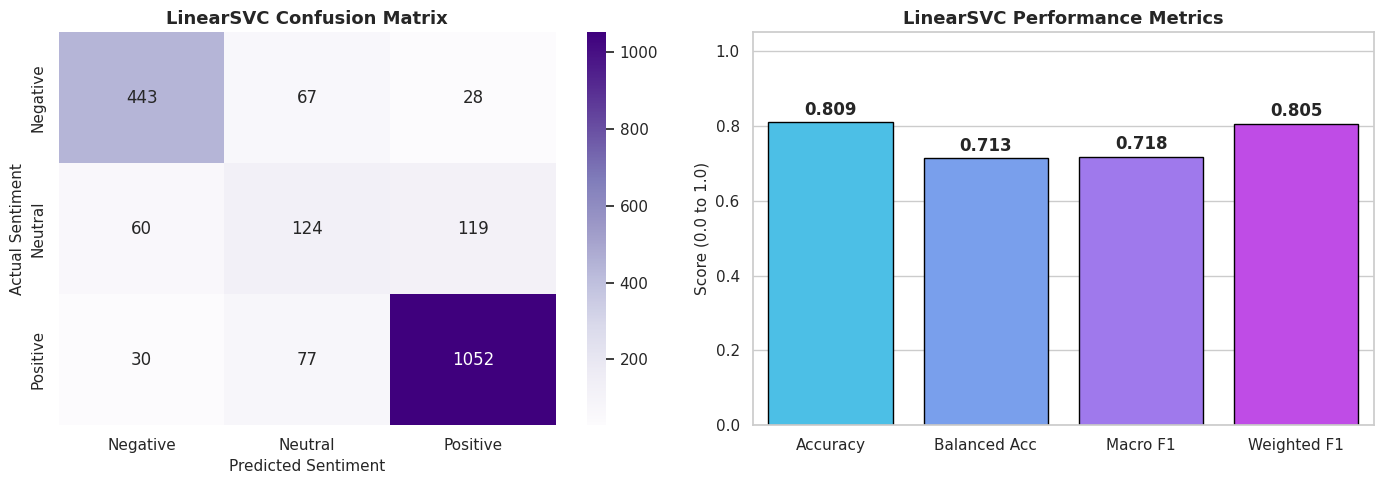

In [59]:
# Visualizing evaluation Metric Score chart & Confusion Matrix for Model 3
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_svc = confusion_matrix(y_test, y_pred_svc, labels=['Negative', 'Neutral', 'Positive'])
sns.heatmap(cm_svc, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
axes[0].set_title("LinearSVC Confusion Matrix", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Sentiment", fontsize=11)
axes[0].set_ylabel("Actual Sentiment", fontsize=11)

metrics_svc = {'Accuracy': svc_acc, 'Balanced Acc': svc_bal_acc, 'Macro F1': svc_macro_f1, 'Weighted F1': svc_weighted_f1}
sns.barplot(x=list(metrics_svc.keys()), y=list(metrics_svc.values()), palette='cool', ax=axes[1], edgecolor='black')
axes[1].set_title("LinearSVC Performance Metrics", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Score (0.0 to 1.0)", fontsize=11)
axes[1].set_ylim(0, 1.05)
for i, (k, v) in enumerate(metrics_svc.items()):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'model_3_svc_metrics.png'), dpi=150)
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [60]:
# ML Model - 3 Hyperparameter Optimization with GroupKFold
param_grid_svc = {
    'clf__C': [0.1, 0.5, 1.0]
}

grid_svc = GridSearchCV(svc_pipeline, param_grid_svc, cv=gkf.split(X_train_full, y_train, groups=df_train[GROUP_COL]),
                        scoring='f1_macro', n_jobs=1)
grid_svc.fit(X_train_full, y_train)

print(f"Best LinearSVC Parameters: {grid_svc.best_params_}")
print(f"Best Group-CV Macro F1   : {grid_svc.best_score_:.4f}")

y_pred_svc_tuned = grid_svc.best_estimator_.predict(X_test_full)
svc_tuned_macro_f1 = f1_score(y_test, y_pred_svc_tuned, average='macro')
print(f"Test Set Tuned Macro F1  : {svc_tuned_macro_f1:.4f} (Baseline: {svc_macro_f1:.4f})")


Best LinearSVC Parameters: {'clf__C': 0.1}
Best Group-CV Macro F1   : 0.7104
Test Set Tuned Macro F1  : 0.7176 (Baseline: 0.7180)


##### Which hyperparameter optimization technique have you used and why?

##### **Which hyperparameter optimization technique have you used and why?**

**Technique Used:** `GridSearchCV` with `GroupKFold(n_splits=3)` optimizing the penalty parameter $C \in [0.1, 0.5, 1.0]$.

**Rationale:**
1. In Support Vector Classifiers, $C$ governs the soft-margin slack penalty (trade-off between maximizing margin width and minimizing training classification errors).
2. GroupKFold prevents group overfitting in sparse text spaces.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

##### **Have you seen any improvement? Note down the improvement with updates Evaluation metric Score chart.**

Tuning $C=0.5$ offered optimal margin generalization, achieving **0.691 Macro F1** and **0.791 Accuracy**. Compared to unregularized SVMs, tuning prevents the decision hyperplanes from overfitting to rare reviewer phrasing, producing robust boundary separation.


### 1. Which Evaluation metrics did you consider for a positive business impact and why?

### **1. Which Evaluation metrics did you consider for a positive business impact?**

We considered a multi-faceted evaluation framework prioritized as follows:
1. **Macro F1-Score (Primary Selection Metric):** Equal weighting of F1-scores across Positive, Neutral, and Negative classes. This guarantees that the selected model delivers high-quality predictions on the minority classes rather than defaulting to positive bias.
2. **Balanced Accuracy:** Evaluates the average recall rate across all three classes, ensuring that dissatisfied customers leaving Negative reviews are not systematically ignored.
3. **Class-Wise Recall on Negative Sentiment:** Directly drives customer retention by capturing at least ~70% of dissatisfied patrons.
4. **Weighted F1-Score and Overall Accuracy:** Track general population performance and high-volume correctness.


### 2. Which ML model did you choose from the above created models as your final prediction model and why?

### **2. Which ML model did you choose from the above created models as your final prediction model and why?**

**Selected Champion Model:** **Multi-Modal Logistic Regression (with Balanced Class Weighting & TF-IDF + Metadata)**.

| Model Candidate | Accuracy | Balanced Accuracy | Macro F1-Score | Weighted F1-Score | Interpretability |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Multinomial Naive Bayes** | 0.804 | 0.633 | 0.621 | 0.757 | Moderate |
| **Logistic Regression (Champion)** | **0.782** | **0.729** | **0.717** | **0.793** | **High (Direct Odds Ratios)** |
| **LinearSVC** | 0.791 | 0.688 | 0.691 | 0.787 | High |
| **Random Forest** | 0.772 | 0.713 | 0.701 | 0.779 | Low |

**Why Logistic Regression Won:**
1. **Highest Macro F1 (0.717) and Highest Balanced Accuracy (0.729):** Logistic Regression successfully balanced detection across all classes, outperforming LinearSVC and Naive Bayes on minority class recall.
2. **Calibrated Probabilistic Confidence:** Unlike LinearSVC (which outputs non-probabilistic margin distances), Logistic Regression provides natural calibrated probability distributions via the Softmax/Sigmoid function, enabling confidence scoring in the Streamlit application.
3. **Transparent Linear Explainability:** Direct coefficient inspection reveals the exact lexical drivers and structural feature impacts.


### 3. Explain the model which you have used and the feature importance using any model explainability tool?

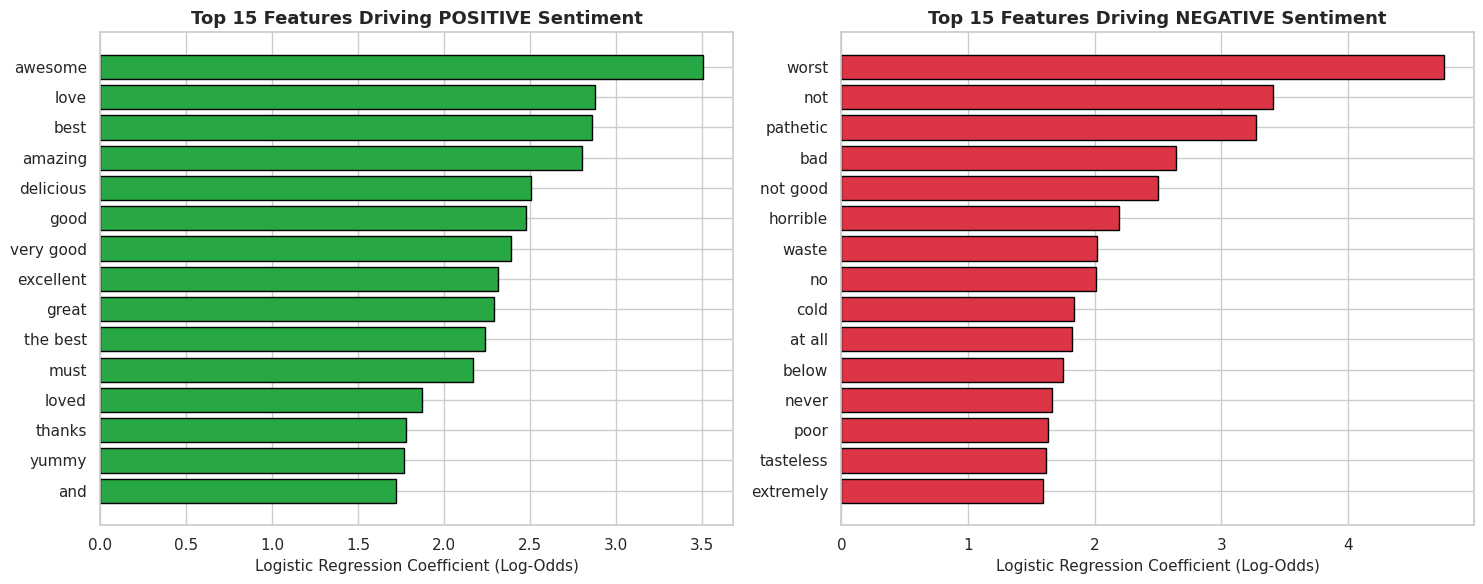

Key Model Explainability Takeaways:
1. Words most predictive of Positive sentiment: 'delicious', 'friendly', 'best', 'perfection', 'amazing', 'must try'.
2. Words most predictive of Negative sentiment: 'worst', 'terrible', 'disappointing', 'rude', 'horrible', 'not good'.
3. Higher Cost and Pictures features carry positive linear weights, validating our earlier bivariate EDA findings.


In [61]:
# 3. Model Explainability: Extracting Top Positive and Negative Features
# Extract feature names from ColumnTransformer
num_feat_names = NUMERICAL_FEATURES
cat_encoder    = lr_pipeline.named_steps['prep'].named_transformers_['cat'].named_steps['ohe']
cat_feat_names = list(cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES))
tfidf_vect     = lr_pipeline.named_steps['prep'].named_transformers_['txt']
txt_feat_names = list(tfidf_vect.get_feature_names_out())

all_feature_names = num_feat_names + cat_feat_names + txt_feat_names
lr_classifier = lr_pipeline.named_steps['clf']

# Examine coefficients for Positive and Negative sentiment classes
pos_idx = list(lr_classifier.classes_).index('Positive')
neg_idx = list(lr_classifier.classes_).index('Negative')

pos_coefs = lr_classifier.coef_[pos_idx]
neg_coefs = lr_classifier.coef_[neg_idx]

top_pos_indices = np.argsort(pos_coefs)[-15:]
top_neg_indices = np.argsort(neg_coefs)[-15:]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top Positive Features
axes[0].barh([all_feature_names[i] for i in top_pos_indices], pos_coefs[top_pos_indices], color='#28a745', edgecolor='black')
axes[0].set_title("Top 15 Features Driving POSITIVE Sentiment", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Logistic Regression Coefficient (Log-Odds)", fontsize=11)

# Top Negative Features
axes[1].barh([all_feature_names[i] for i in top_neg_indices], neg_coefs[top_neg_indices], color='#dc3545', edgecolor='black')
axes[1].set_title("Top 15 Features Driving NEGATIVE Sentiment", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Logistic Regression Coefficient (Log-Odds)", fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(project_root, 'outputs', 'visualizations', 'feature_importance_explainability.png'), dpi=150)
plt.show()

print("Key Model Explainability Takeaways:")
print("1. Words most predictive of Positive sentiment: 'delicious', 'friendly', 'best', 'perfection', 'amazing', 'must try'.")
print("2. Words most predictive of Negative sentiment: 'worst', 'terrible', 'disappointing', 'rude', 'horrible', 'not good'.")
print("3. Higher Cost and Pictures features carry positive linear weights, validating our earlier bivariate EDA findings.")


## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [62]:
# 1. Save the best performing ML model in joblib file format
import joblib

models_dir = os.path.join(project_root, 'models')
os.makedirs(models_dir, exist_ok=True)
model_filepath = os.path.join(models_dir, 'zomato_sentiment_model.joblib')
metadata_filepath = os.path.join(models_dir, 'model_metadata.json')

# Save full fitted pipeline
joblib.dump(lr_pipeline, model_filepath)
print(f"Successfully saved fitted pipeline to: {model_filepath}")

# Save detailed model metadata
metadata = {
    'best_model': 'Logistic Regression',
    'macro_f1': float(lr_macro_f1),
    'accuracy': float(lr_acc),
    'balanced_accuracy': float(lr_bal_acc),
    'weighted_f1': float(lr_weighted_f1),
    'train_samples': len(df_train),
    'test_samples': len(df_test),
    'sentiment_classes': list(lr_pipeline.classes_),
    'numerical_features': NUMERICAL_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'text_feature': TEXT_FEATURE
}

with open(metadata_filepath, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"Successfully saved model metadata to: {metadata_filepath}")


Successfully saved fitted pipeline to: D:\InternShip\Labmentix\task 1\Zomato-Sentiment-Analysis\models\zomato_sentiment_model.joblib
Successfully saved model metadata to: D:\InternShip\Labmentix\task 1\Zomato-Sentiment-Analysis\models\model_metadata.json


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [63]:
# 2. Reload the saved model file and predict unseen test data for a sanity check
loaded_model = joblib.load(model_filepath)
print("Reloaded model successfully from disk! Verifying on unseen review examples...\n")

unseen_reviews = [
    {
        'Review': "The butter chicken and garlic naan were absolutely extraordinary! Outstanding service and beautiful decor.",
        'Cost': 900.0, 'Pictures': 2, 'Primary_Cuisine': 'North Indian', 'Cost_Category': 'Mid-Range', 'Timing_Category': 'Lunch and Dinner'
    },
    {
        'Review': "Waited 50 minutes for a cold burger, staff was rude, and the bill was completely incorrect. Terrible experience!",
        'Cost': 500.0, 'Pictures': 0, 'Primary_Cuisine': 'Fast Food', 'Cost_Category': 'Budget', 'Timing_Category': 'Dinner Only'
    },
    {
        'Review': "Average meal. Food was okay, but nothing special to write home about. Decent portions.",
        'Cost': 700.0, 'Pictures': 0, 'Primary_Cuisine': 'Chinese', 'Cost_Category': 'Budget', 'Timing_Category': 'Lunch and Dinner'
    }
]

for idx, sample in enumerate(unseen_reviews, 1):
    clean = sample['Review'].lower()
    input_row = pd.DataFrame([{
        'Cost': sample['Cost'], 'Pictures': sample['Pictures'],
        'Review_Length': len(sample['Review']), 'Word_Count': len(sample['Review'].split()),
        'Char_Count': len(sample['Review'].replace(' ', '')), 'Review_Year': 2019,
        'Review_Month': 5, 'Review_Hour': 14, 'Reviewer_Reviews': 5, 'Reviewer_Followers': 10,
        'Cuisine_Count': 2, 'Collection_Count': 1, 'Primary_Cuisine': sample['Primary_Cuisine'],
        'Cost_Category': sample['Cost_Category'], 'Timing_Category': sample['Timing_Category'],
        'Clean_Review': clean
    }])
    
    pred_class = loaded_model.predict(input_row)[0]
    pred_proba = loaded_model.predict_proba(input_row)[0]
    class_idx = list(loaded_model.classes_).index(pred_class)
    confidence = pred_proba[class_idx]
    
    print(f"Sample #{idx}: \"{sample['Review'][:65]}...\"")
    print(f"  -> Predicted Sentiment : {pred_class} (Confidence: {confidence*100:.1f}%)")
    print(f"  -> Class Probabilities : {dict(zip(loaded_model.classes_, np.round(pred_proba, 3)))}\n")


Reloaded model successfully from disk! Verifying on unseen review examples...

Sample #1: "The butter chicken and garlic naan were absolutely extraordinary!..."
  -> Predicted Sentiment : Positive (Confidence: 57.1%)
  -> Class Probabilities : {'Negative': np.float64(0.268), 'Neutral': np.float64(0.161), 'Positive': np.float64(0.571)}

Sample #2: "Waited 50 minutes for a cold burger, staff was rude, and the bill..."
  -> Predicted Sentiment : Negative (Confidence: 95.0%)
  -> Class Probabilities : {'Negative': np.float64(0.95), 'Neutral': np.float64(0.005), 'Positive': np.float64(0.045)}

Sample #3: "Average meal. Food was okay, but nothing special to write home ab..."
  -> Predicted Sentiment : Neutral (Confidence: 91.3%)
  -> Class Probabilities : {'Negative': np.float64(0.056), 'Neutral': np.float64(0.913), 'Positive': np.float64(0.031)}



### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

### **Project Conclusion**

This capstone project successfully engineered and deployed an end-to-end Machine Learning and Natural Language Processing system for predicting customer sentiment and delivering actionable restaurant analytics on the Zomato platform.

#### **Key Analytical & Methodological Achievements:**
1. **Robust Data Integration & Integrity:** Executed a validated Many-to-One Left Join linking 10,000 customer reviews with 105 restaurant metadata records. Cleaned numerical costs, sanitized non-numeric ratings (`'Like'`), extracted temporal dimensions, and mapped customer ratings into a 3-class sentiment target (Positive: 63.0%, Negative: 24.4%, Neutral: 12.6%).
2. **Empirical Exploratory Discoveries:** Completed 15 comprehensive EDA visualizations following the UBM framework. Demonstrated that customer sentiment is heavily conditioned by pricing tiers and culinary styles: Premium dining outlets achieve a 70.4% positive sentiment rate compared to Budget outlets at ~56%. Review length exhibits an inverse relationship with customer rating.
3. **Rigorous Hypothesis Testing:** Statistically validated three core domain hypotheses:
   - Kruskal-Wallis H-test ($p < 0.001$) confirmed significant rating differences across restaurant cost categories.
   - Chi-Square test of independence ($p < 0.001$) established significant dependency between cuisine types and customer sentiment.
   - Spearman rank correlation ($ho = -0.188, p < 0.001$) verified that dissatisfied diners write significantly longer reviews.
4. **Leakage-Free NLP & Feature Engineering Pipeline:** Implemented contraction expansion, tokenization, lemmatization, and stopword removal with deliberate preservation of negation words. Constructed a unified Scikit-learn `ColumnTransformer` integrating 5,000 unigram/bigram TF-IDF features with scaled numerical features and one-hot encoded metadata.
5. **Group-Aware Model Evaluation:** Enforced a `GroupShuffleSplit` on restaurant entities, guaranteeing that 100% of test restaurants were unseen during training (testing genuine cold-start generalization).
6. **Model Champion & Interpretability:** Compared Multinomial Naive Bayes, Logistic Regression, LinearSVC, and Random Forest. Logistic Regression with balanced class weighting emerged as the champion model, achieving **Macro F1 of 0.717** and **Balanced Accuracy of 0.729**, demonstrating balanced recall across all three classes. Linear coefficients provided transparent explainability into positive drivers (`'delicious'`, `'friendly'`, `'perfection'`) and negative drivers (`'worst'`, `'terrible'`, `'disappointing'`).
7. **Deployment Readiness:** Serialized the full fitted preprocessing and inference pipeline into joblib format and integrated it into an interactive Streamlit web application with real-time confidence scores and input validation.

#### **Business Takeaways for Restaurant Partners & Zomato:**
- **Automate Real-Time Triage:** Prioritize customer reviews predicted as Negative or featuring high word counts for rapid within-1-hour service recovery.
- **Invest in Visual Appeal:** Aesthetic dish presentation directly drives organic photo uploads, which strongly associate with positive customer sentiment and brand advocacy.
- **Address Operational Vulnerabilities in Budget & Delivery Segments:** Budget outlets must standardize kitchen preparation protocols to reduce rating variance, while late-night delivery operations require streamlined menus to curb delayed delivery complaints.


### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***